### Variance change point: CUSUM (`llr_pair`) analysis

Same protocol as the `_mean` notebooks, but here the **variance** of the input noise changes, not the mean. The current stays at I_0 = 60 pA (step height 0). The piecewise-constant Gaussian noise (resampled at 50 Hz) has variance σ² before the change point and σ² + Δσ² after it. T = 10 s, change at 5 s, 100 repeats. Every autapse strength f gets the same noise within each (σ², Δσ²) block.

Data: `simulate_w_cusum(..., change = 'variance')` in `CPA_with_AQUA.py`, which writes `CPA_cusum_variance_N100_llr_pair.pickle` and `CPA_cusum_variance_N100_spikes.pickle`.
- `variance` is the baseline (pre-change) variance σ².
- `variance_step` is the jump Δσ². It plays the role `step_height` plays in the mean case, and `step_height` is always 0.
- The Fisher measures are about the noise variance (÷ Δσ²), so their units are nats/pA⁴.

This notebook combines the three mean-case notebooks:
1. example pre/post ISI and ISI-pair distributions (`CPA_divergences_CUSUM_mean.ipynb`)
2. score and AUC (`AQUA_CPA_plots_CUSUM_mean.ipynb`)
3. change point errors, hit rate and tolerance ROC (`CPA_CP_estimate_CUSUM_mean.ipynb`)
4. divergence measures and model-free distances (`CPA_divergences_CUSUM_mean.ipynb`)

In [1]:
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
import pickle
import seaborn as sns
sns.set_theme()

from CPA_with_AQUA import *

In [2]:
tag = 'N100'
outfile = f'CPA_cusum_variance_{tag}_llr_pair.pickle'
spike_file = f'CPA_cusum_variance_{tag}_spikes.pickle'
SAVE = False
DROP_ZERO_BASELINE = True   # divergence section only: at σ² = 0 the pre ISIs are almost fixed, so the fits are very narrow

true_cp = 5000              # ms
STEP = 'variance_step'      # the change size column
XLABEL = 'Variance jump Δσ² [pA²]'

with open(outfile, 'rb') as file:
    data = pickle.load(file)
method = data['method'].iloc[0]
assert (data['step_height'] == 0).all()

variances = np.sort(data['variance'].unique())
f_vals = np.sort(data['autapse f'].unique())
steps = np.sort(data[STEP].unique())
print(f"method: {method}, rows: {len(data)}, repeats: {data['N'].nunique()}")
print(f"baseline variances: {variances}\nvariance jumps: {steps}\nf: {f_vals}")

# the divergence measures are the same for every repeat of a condition: keep one row per condition
cond_cols = ['variance', STEP, 'autapse f']
cond_all = data.drop_duplicates(cond_cols).reset_index(drop = True)

method: llr_pair, rows: 35200, repeats: 100
baseline variances: [ 0.  12.5 25.  50. ]
variance jumps: [  0   5  10  25  50 100 150 200]
f: [  0 100 150 200 220 240 260 280 300 350 400]


In [3]:
def by_variance(df, y, ylabel, log = False, hue = 'autapse f', title = None, xlim = None):
    '''one panel per baseline variance, one line per autapse strength, against the variance jump'''
    vs = np.sort(df['variance'].unique())
    fig, ax = plt.subplots(1, len(vs), figsize = (4.5*len(vs), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, v in enumerate(vs):
        fig, ax[n] = psychometric_curve(df[df['variance'] == v], x = STEP, y = y, hue = hue,
                                        fig = fig, ax = ax[n], add_colorbar = n == len(vs) - 1)
        ax[n].set_xlabel(XLABEL)
        ax[n].set_title(f'Baseline variance σ² = {v}')
        if log: ax[n].set_yscale('log')
        if xlim is not None: ax[n].set_xlim(xlim)
    ax[0].set_ylabel(ylabel)
    fig.suptitle(title if title is not None else f'{y} ({method})', y = 1.02)
    return fig, ax


def by_neuron(df, y, ylabel, log = False, title = None):
    '''one panel per autapse strength, one line per baseline variance, against the variance jump'''
    fs = np.sort(df['autapse f'].unique())
    fig, ax = plt.subplots(1, len(fs), figsize = (2.2*len(fs), 4), sharey = True, squeeze = False)
    ax = ax[0]
    for n, f in enumerate(fs):
        fig, ax[n] = psychometric_curve(df[df['autapse f'] == f], x = STEP, y = y, hue = 'variance',
                                        fig = fig, ax = ax[n], add_colorbar = n == len(fs) - 1,
                                        colorbar_label = 'Baseline variance σ²')
        ax[n].set_xlabel('Δσ² [pA²]')
        ax[n].set_title(f'f = {np.round(f, 0)} pA')
        if log: ax[n].set_yscale('log')
    ax[0].set_ylabel(ylabel)
    fig.suptitle(title if title is not None else f'{y} ({method})', y = 1.04)
    return fig, ax

#### Example pre/post ISI distributions
Pooled ISIs before and after the change, with autapse strength f increasing from left to right. Larger noise mainly broadens the ISI distribution and adds short ISIs (the f-I curve is convex near threshold, so extra variance also raises the mean rate). Corner of each panel: JS, Jeffreys J and KS for that condition.

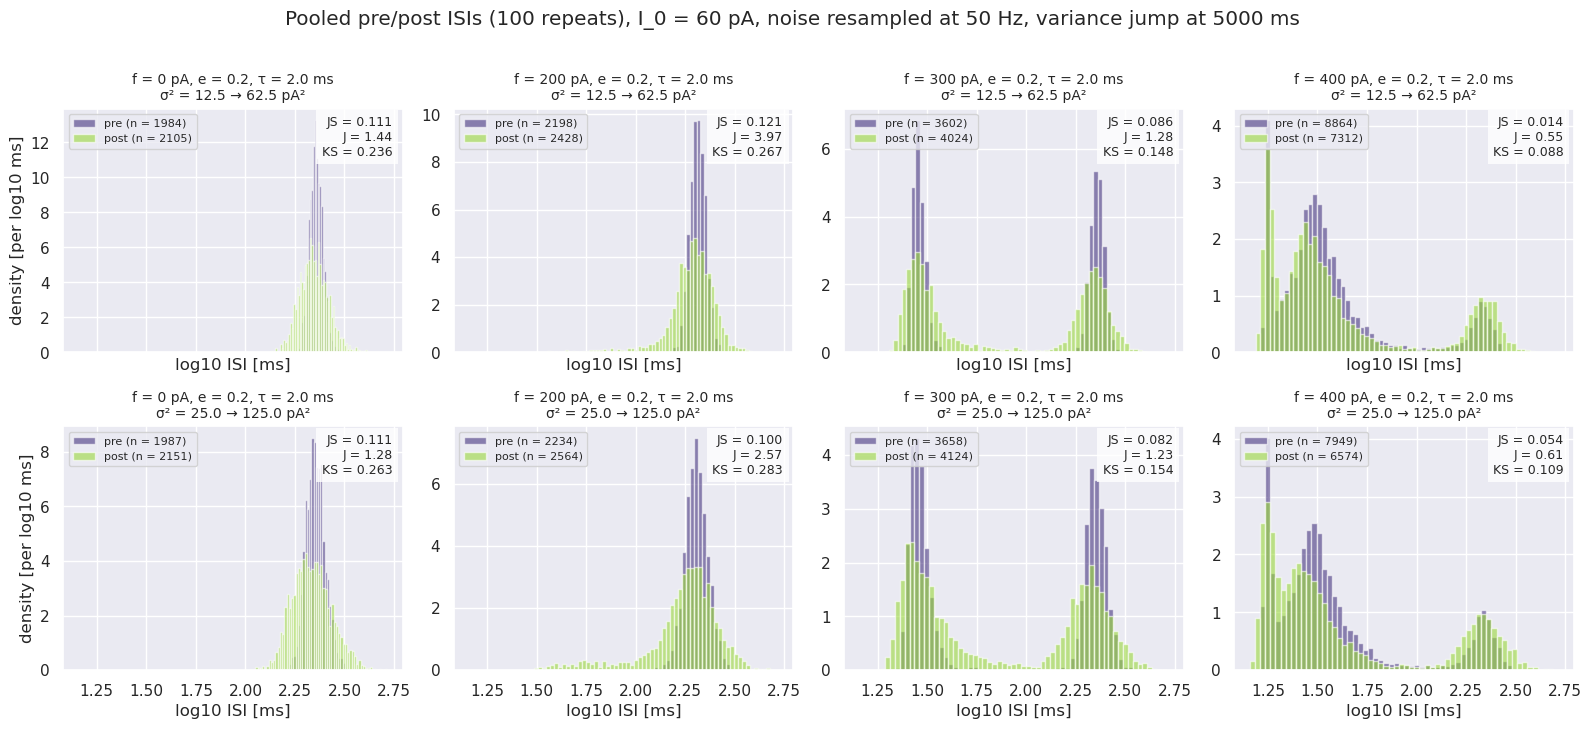

In [4]:
EXAMPLES = [(12.5, 50), (25.0, 100)]    # (baseline variance, variance jump) rows
EXAMPLE_F = [0, 200, 300, 400]          # columns
T_DISCARD = 200                          # ms, as in simulate_w_cusum

with open(spike_file, 'rb') as file:
    saved = pickle.load(file)
assert saved['change'] == 'variance'
sim = {k: p.default for k, p in inspect.signature(simulate_runs).parameters.items()
       if p.default is not inspect.Parameter.empty}


def cond_row(v, dv, f):
    return cond_all[(cond_all['variance'] == v) & (cond_all[STEP] == dv) & (cond_all['autapse f'] == f)].iloc[0]


fig, ax = plt.subplots(len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.6*len(EXAMPLES)), sharex = True, squeeze = False)
for r, (v, dv) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        trials = [spike_isis(saved['spikes'][(rep, v, dv, f)], T_DISCARD) for rep in range(saved['N_repeats'])]
        pre, post = reference_isis(trials, saved['changepoint'])
        bins = np.linspace(np.log10(min(pre.min(), post.min())), np.log10(max(pre.max(), post.max())), 60)
        ax[r, c].hist(np.log10(pre), bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.15), label = f'pre (n = {len(pre)})')
        ax[r, c].hist(np.log10(post), bins = bins, density = True, alpha = 0.6, color = plt.cm.viridis(0.85), label = f'post (n = {len(post)})')
        ax[r, c].set_xlabel('log10 ISI [ms]')

        row = cond_row(v, dv, f)
        ax[r, c].set_title(f'f = {f} pA, e = {sim["e"]}, τ = {sim["tau"]} ms\n'
                           f'σ² = {v} → {v + dv} pA²', fontsize = 10)
        ax[r, c].text(0.97, 0.97, f"JS = {row['JS divergence']:.3f}\nJ = {row['divergence']:.2f}\n"
                                  f"KS = {row['KS distance']:.3f}",
                      transform = ax[r, c].transAxes, ha = 'right', va = 'top', fontsize = 9,
                      bbox = dict(facecolor = 'white', alpha = 0.8, edgecolor = 'none'))
        ax[r, c].legend(loc = 'upper left', fontsize = 8)
    ax[r, 0].set_ylabel('density [per log10 ms]')
fig.suptitle(f'Pooled pre/post ISIs ({saved["N_repeats"]} repeats), I_0 = {sim["I_0"]} pA, '
             f'noise resampled at {sim["noise_rate"]} Hz, variance jump at {saved["changepoint"]} ms', y = 1.01)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/var_{tag}_example_pre_post_ISIs.png', bbox_inches = 'tight')

#### Example pre/post ISI-pair distributions (`llr_pair`)
Consecutive ISI pairs (ISI$_{n-1}$, ISI$_n$), the distributions `llr_pair` actually compares. Same conditions as above: a pre row and a post row per example, one column per f. The colour scale is log density, shared by all panels.

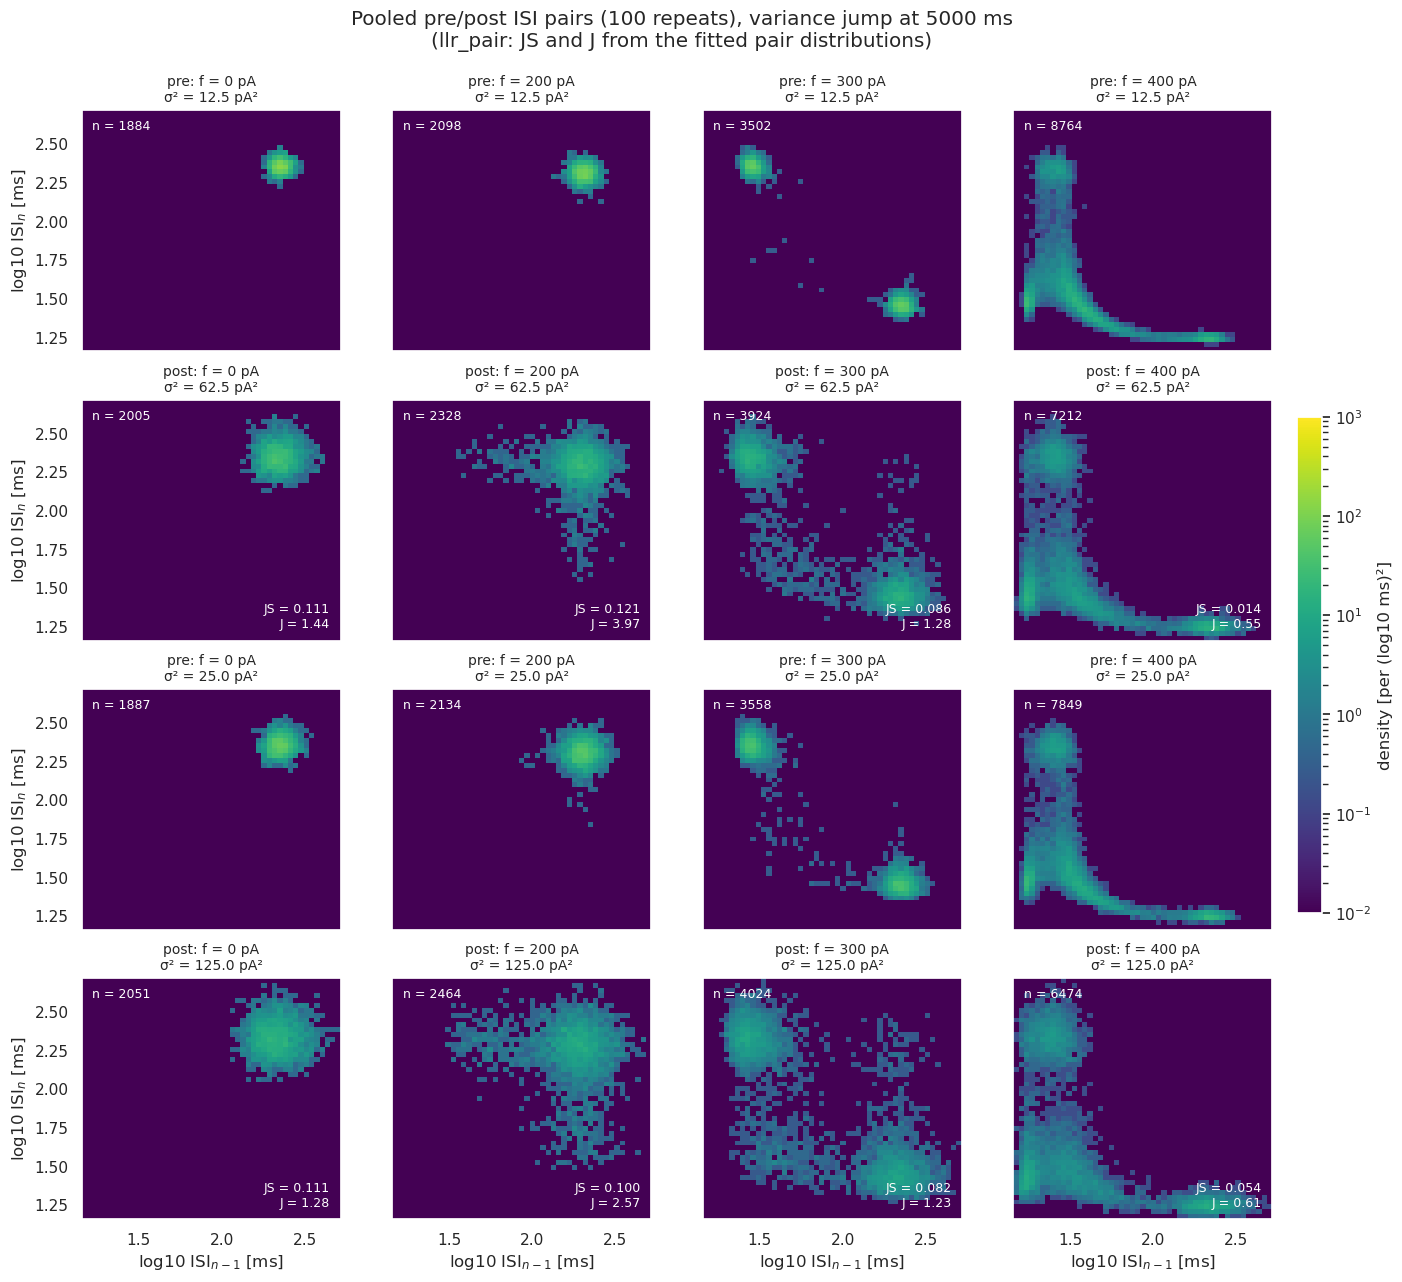

In [5]:
pairs = {}
for v, dv in EXAMPLES:
    for f in EXAMPLE_F:
        trials = [spike_isis(saved['spikes'][(rep, v, dv, f)], T_DISCARD) for rep in range(saved['N_repeats'])]
        pairs[(v, dv, f)] = [np.log10(p) for p in reference_pairs(trials, saved['changepoint'])]
lo = min(p.min() for pp in pairs.values() for p in pp if len(p))
hi = max(p.max() for pp in pairs.values() for p in pp if len(p))
bins = np.linspace(lo, hi, 50)
norm = LogNorm(vmin = 1e-2, vmax = 1e3)

fig, ax = plt.subplots(2*len(EXAMPLES), len(EXAMPLE_F), figsize = (4*len(EXAMPLE_F), 3.6*2*len(EXAMPLES)),
                       sharex = True, sharey = True, squeeze = False)
for i, (v, dv) in enumerate(EXAMPLES):
    for c, f in enumerate(EXAMPLE_F):
        row = cond_row(v, dv, f)
        for j, (name, p) in enumerate(zip(['pre', 'post'], pairs[(v, dv, f)])):
            a = ax[2*i + j, c]
            *_, im = a.hist2d(p[:, 0], p[:, 1], bins = bins, density = True, cmap = 'viridis', norm = norm)
            a.set_facecolor(plt.cm.viridis(0))
            a.grid(False)
            a.set_title(f'{name}: f = {f} pA\nσ² = {v if name == "pre" else v + dv} pA²', fontsize = 10)
            a.text(0.04, 0.96, f'n = {len(p)}', transform = a.transAxes, ha = 'left', va = 'top',
                   fontsize = 9, color = 'white')
        ax[2*i + 1, c].text(0.96, 0.04, f"JS = {row['JS divergence']:.3f}\nJ = {row['divergence']:.2f}",
                            transform = ax[2*i + 1, c].transAxes, ha = 'right', va = 'bottom', fontsize = 9, color = 'white')
for a in ax[-1]:
    a.set_xlabel('log10 ISI$_{n-1}$ [ms]')
for a in ax[:, 0]:
    a.set_ylabel('log10 ISI$_n$ [ms]')
fig.colorbar(im, ax = ax, label = 'density [per (log10 ms)²]', fraction = 0.02, pad = 0.02)
fig.suptitle(f'Pooled pre/post ISI pairs ({saved["N_repeats"]} repeats), variance jump at {saved["changepoint"]} ms\n'
             f'({method}: JS and J from the fitted pair distributions)', y = 0.95)
if SAVE: plt.savefig(f'./plots/var_{tag}_example_pre_post_ISI_pairs.png', bbox_inches = 'tight')

### 1. Score
`score` = mean LLR after the estimated CP − mean before (about 0 with no change). `score per s` is the evidence rate in each trial. Mean ± SD over repeats.

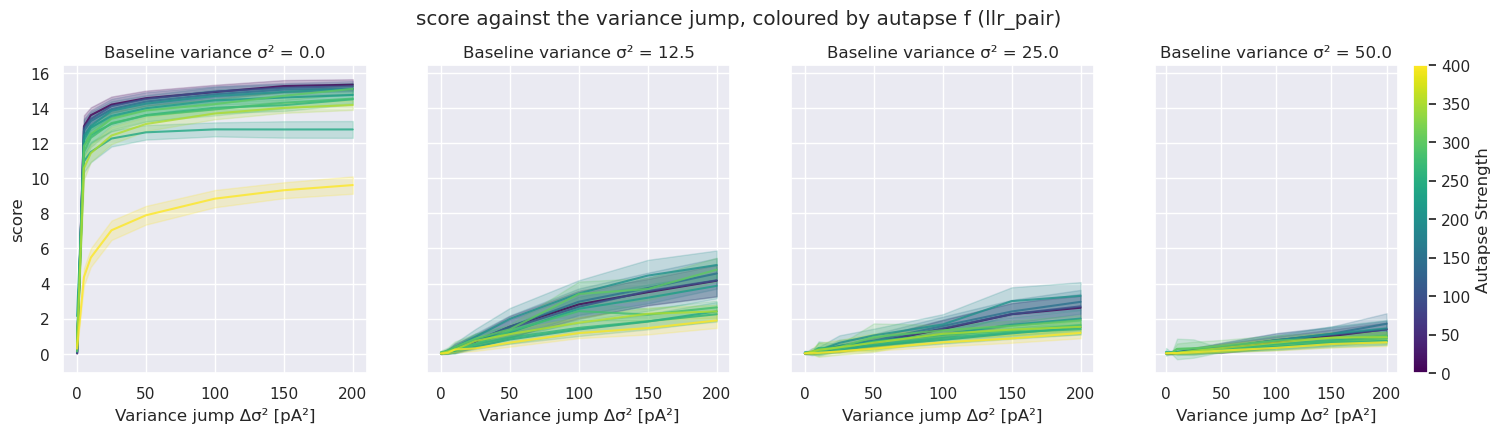

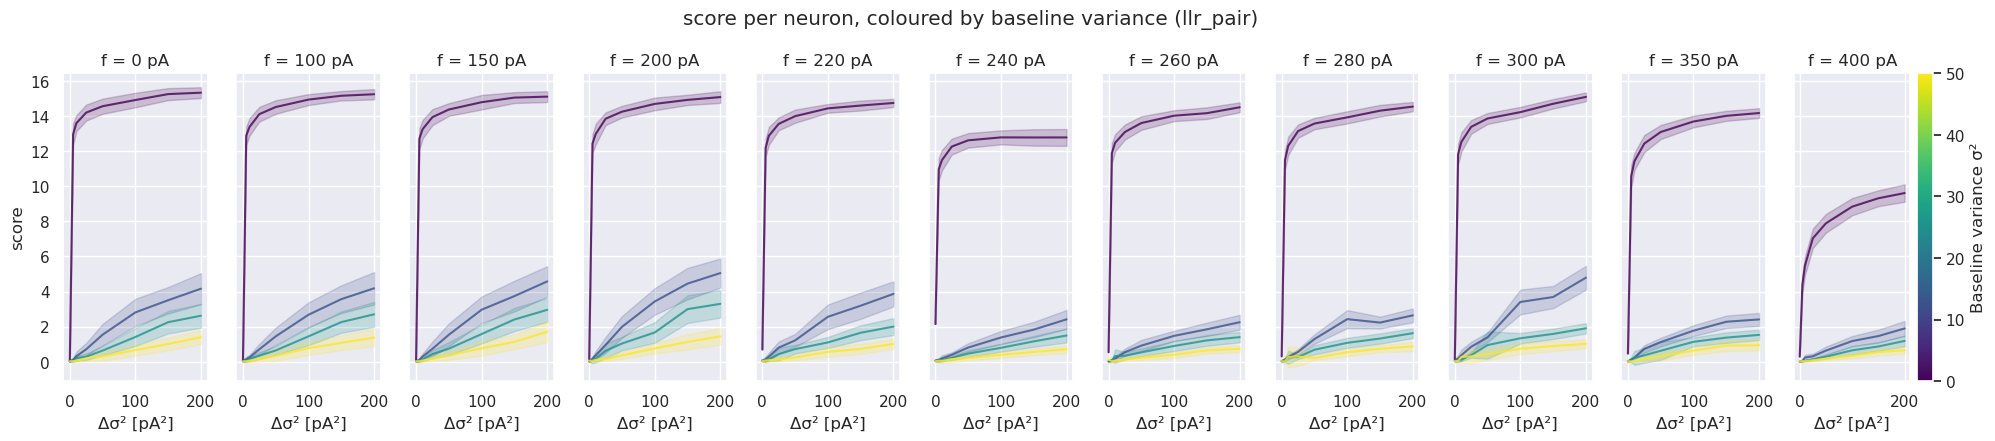

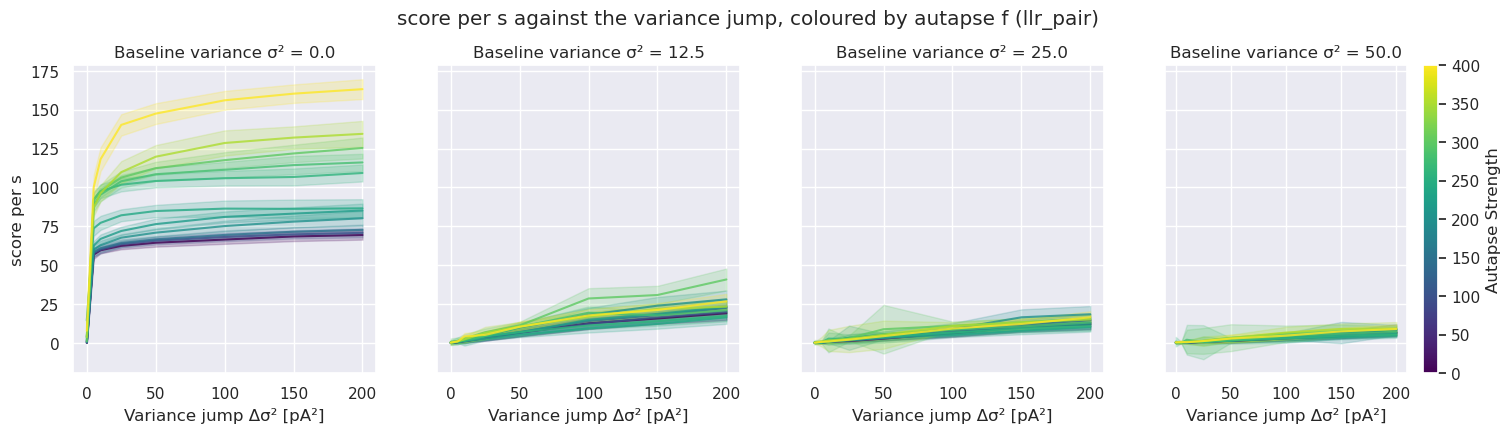

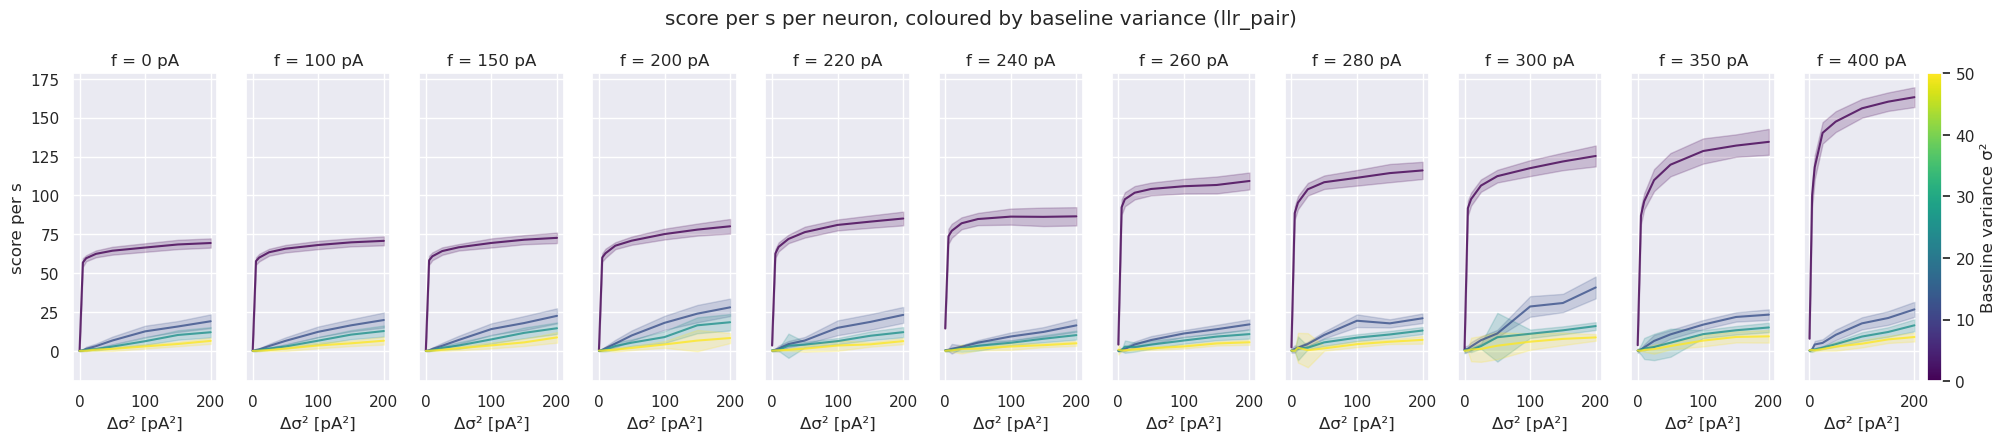

In [6]:
for y in ['score', 'score per s']:
    by_variance(data, y, y, title = f'{y} against the variance jump, coloured by autapse f ({method})')
    if SAVE: plt.savefig(f'./plots/var_{tag}_{y.replace(" ", "_")}_diff_V.png', bbox_inches = 'tight')
    plt.show()
    by_neuron(data, y, y, title = f'{y} per neuron, coloured by baseline variance ({method})')
    if SAVE: plt.savefig(f'./plots/var_{tag}_{y.replace(" ", "_")}_diff_autapse.png', bbox_inches = 'tight')
    plt.show()

#### Area under the score vs Δσ² curve
One AUC per neuron, baseline variance and repeat (normalised, i.e. the mean over Δσ²). Error bands: 90 % CI over repeats.

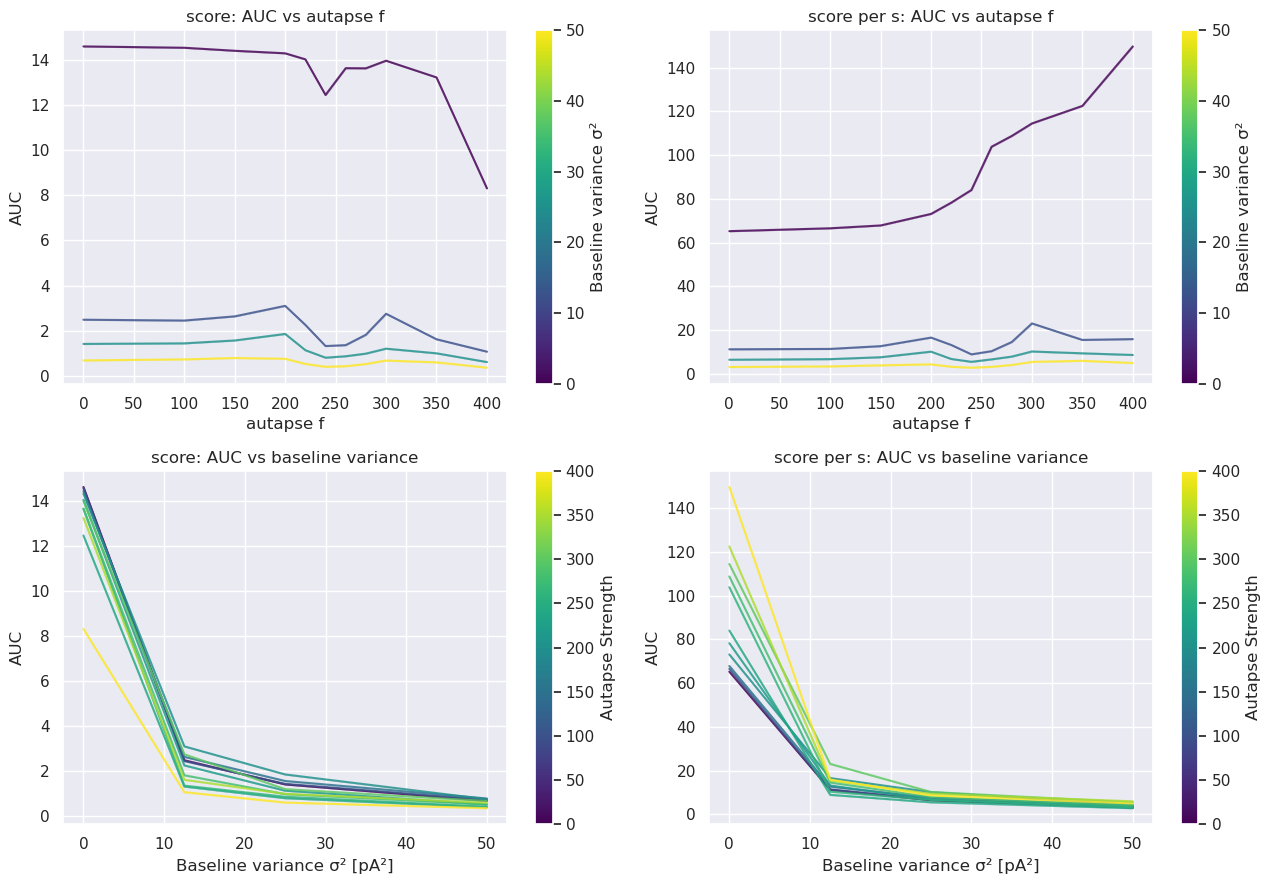

In [7]:
fig, ax = plt.subplots(2, 2, figsize = (13, 9))
for n, y in enumerate(['score', 'score per s']):
    auc = curve_auc(data, y = y, x = STEP, normalise = True)
    fig, ax[0, n] = auc_plot(auc, fig = fig, ax = ax[0, n], colorbar_label = 'Baseline variance σ²')
    ax[0, n].set_title(f'{y}: AUC vs autapse f')
    fig, ax[1, n] = auc_plot(auc, x = 'variance', hue = 'autapse f', fig = fig, ax = ax[1, n],
                             colorbar_label = 'Autapse Strength')
    ax[1, n].set_title(f'{y}: AUC vs baseline variance')
    ax[1, n].set_xlabel('Baseline variance σ² [pA²]')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/var_{tag}_score_AUC.png', bbox_inches = 'tight')

### 2. Change point estimates
#### Estimated − true change point

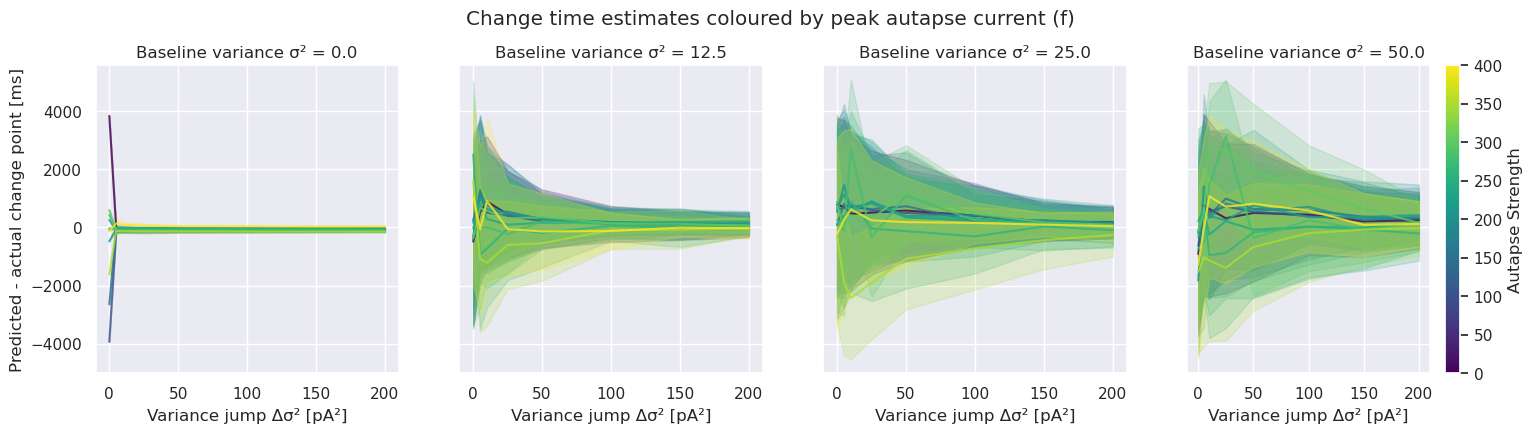

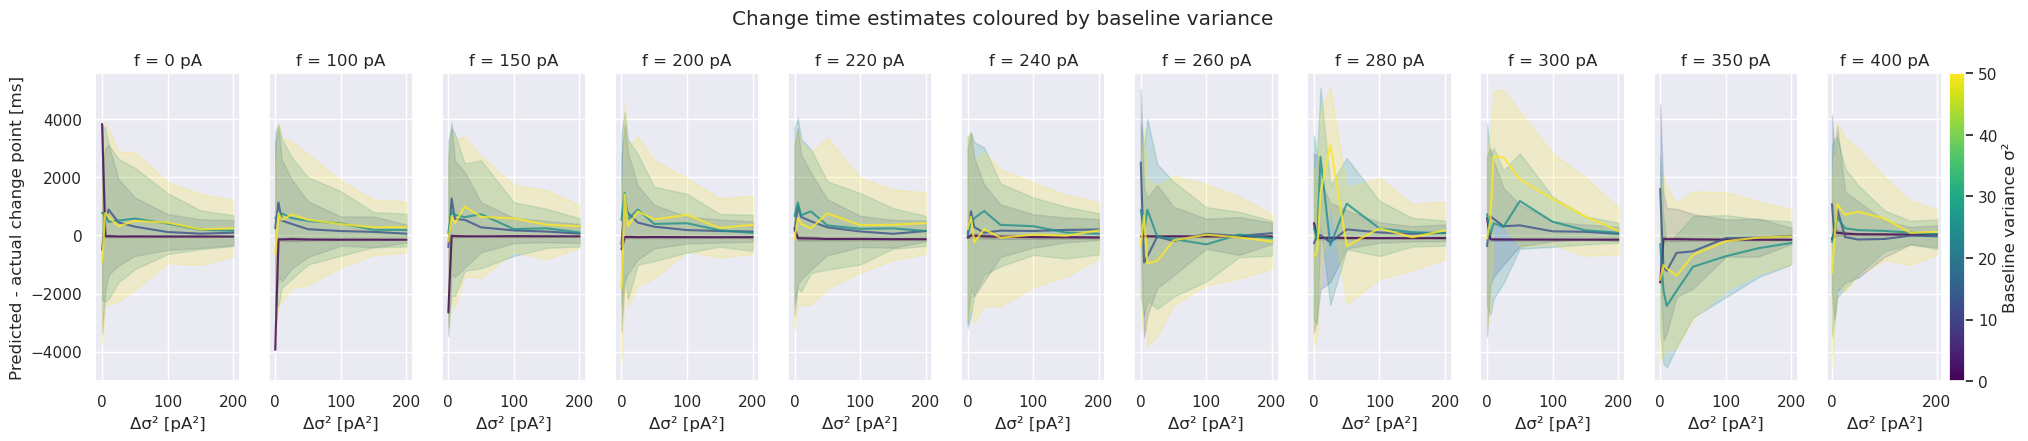

In [8]:
data['delta_CP'] = data['change point'] - true_cp     # ms

by_variance(data, 'delta_CP', 'Predicted - actual change point [ms]',
            title = 'Change time estimates coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/var_{tag}_CP_diff_V.png', bbox_inches = 'tight')
plt.show()
by_neuron(data, 'delta_CP', 'Predicted - actual change point [ms]',
          title = 'Change time estimates coloured by baseline variance')
if SAVE: plt.savefig(f'./plots/var_{tag}_CP_diff_autapse.png', bbox_inches = 'tight')
plt.show()

#### Weighted / L1 / L2 change point error
e = |CP − true_cp| per condition, pooled over repeats. L1 = mean(e), L2 = √mean(e²). The weighted error uses inverse-distance weights 1 / (e + 1 ms), so it is dominated by near-exact hits.

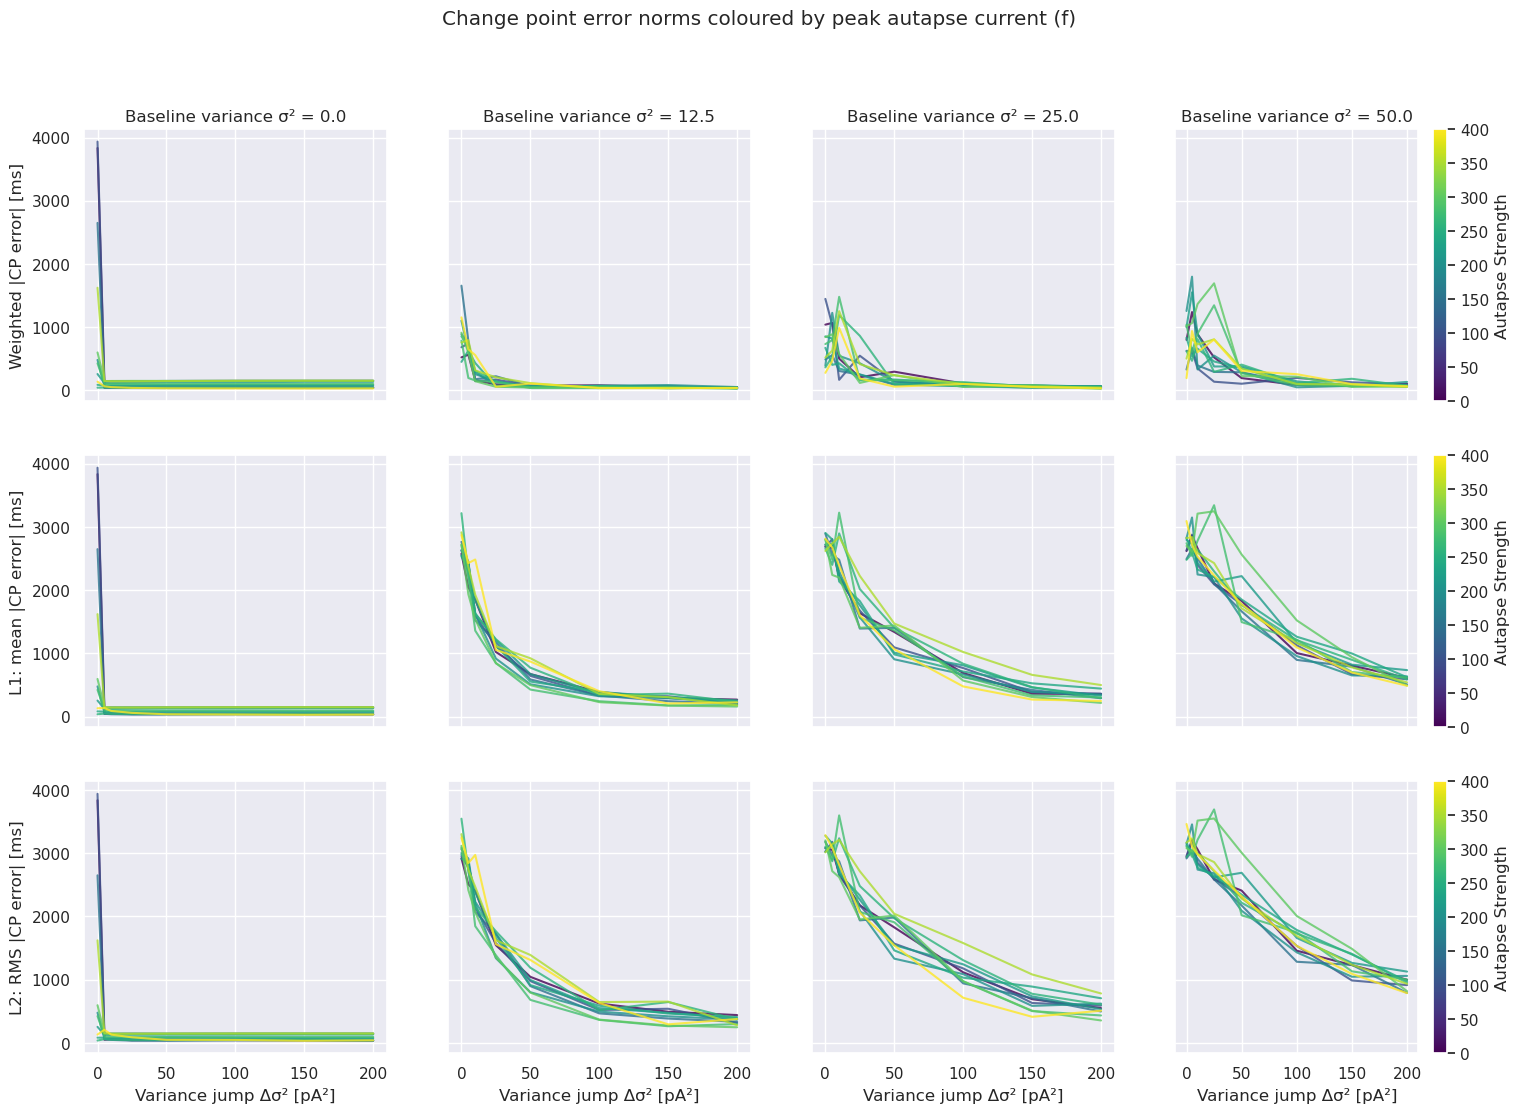

In [9]:
group_cols = ['autapse f', 'variance', STEP]
acc = weighted_cp_distance(data, true_cp, group_cols = group_cols, eps = 1.)
norms = cp_error_norms(data, true_cp, group_cols = group_cols)
errs = acc.merge(norms.drop(columns = 'n'), on = group_cols)

metrics = {'weighted |error|': 'Weighted |CP error| [ms]',
           'L1 |error|': 'L1: mean |CP error| [ms]',
           'L2 |error|': 'L2: RMS |CP error| [ms]'}

fig, ax = plt.subplots(len(metrics), len(variances), figsize = (18, 4 * len(metrics)), sharey = 'row', sharex = 'col')
for m, (metric, label) in enumerate(metrics.items()):
    for n, v in enumerate(variances):
        fig, ax[m, n] = psychometric_curve(errs[errs['variance'] == v], x = STEP, y = metric, hue = 'autapse f',
                                           fig = fig, ax = ax[m, n], add_colorbar = (n == len(variances) - 1))
        ax[m, n].set_ylabel(label if n == 0 else '')
        if m == 0: ax[m, n].set_title(f'Baseline variance σ² = {v}')
        ax[m, n].set_xlabel(XLABEL if m == len(metrics) - 1 else '')
fig.suptitle('Change point error norms coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/var_{tag}_CP_error_norms.png', bbox_inches = 'tight')

#### Hit rate against tolerance: P(|CP − true_cp| ≤ tol)
The tolerance is either a constant in ms or a multiple of each condition's mean ISI (this corrects for firing rate). Per-neuron panels show baseline variance `v_plot`, with curves coloured by Δσ². Below them: the area under each hit-rate curve against Δσ².

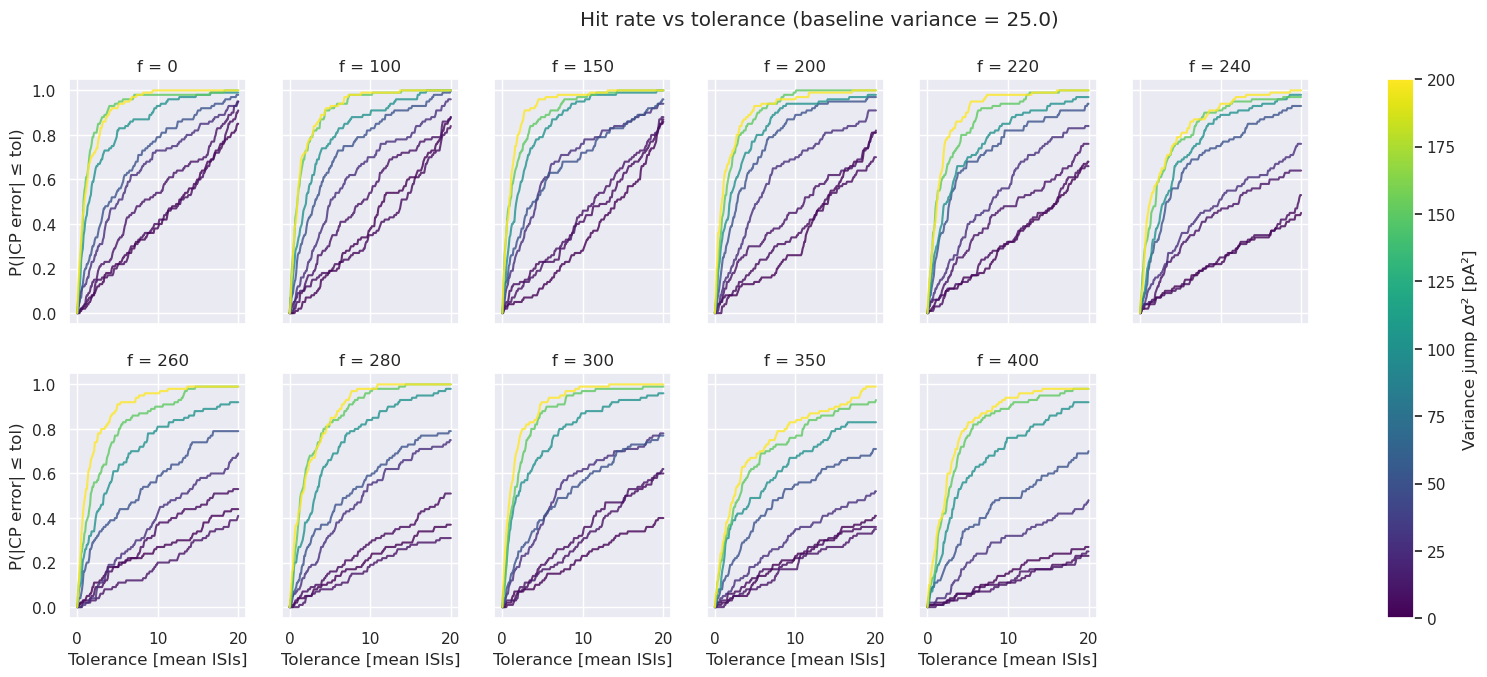

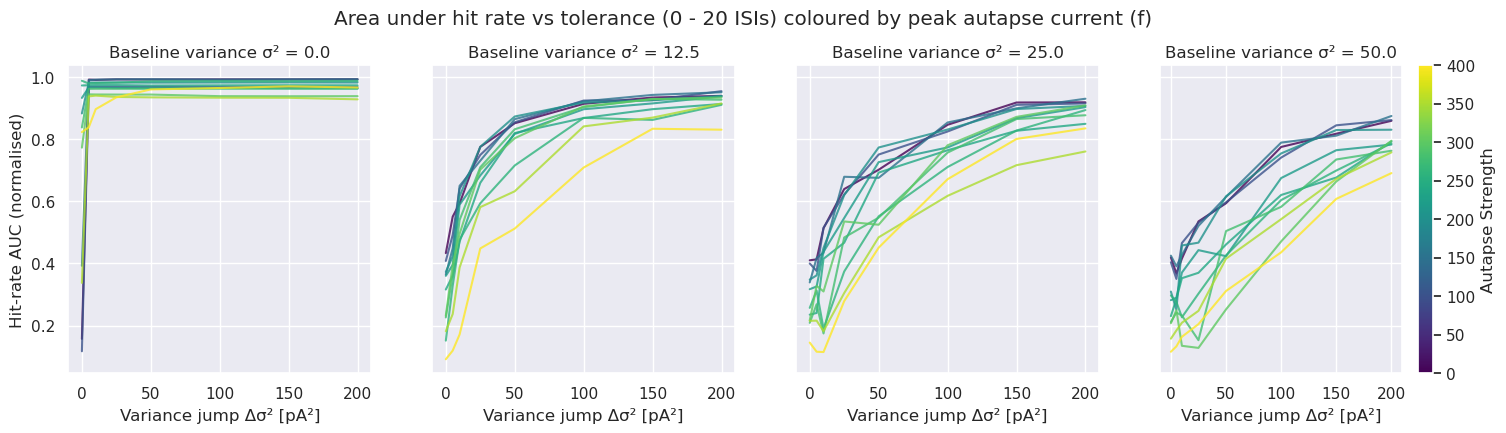

In [10]:
TOL_MODE = 'isi'        # 'isi' or 'ms'
tol_max_ms = 1000       # 'ms' mode: tolerances 0 - tol_max_ms
k_max = 20              # 'isi' mode: tolerances 0 - k_max ISIs
v_plot = 25.0           # baseline variance shown in the per-neuron panels

isi_df = mean_isi(saved['spikes'], step_col = STEP)

if TOL_MODE == 'isi':
    tols, tol_label = np.linspace(0, k_max, 201), 'Tolerance [mean ISIs]'
    hits = hit_rate_curves(data, true_cp, tols, isi_df = isi_df, group_cols = group_cols)
else:
    tols, tol_label = np.linspace(0, tol_max_ms, 201), 'Tolerance [ms]'
    hits = hit_rate_curves(data, true_cp, tols, group_cols = group_cols)

hit_auc = curve_auc(hits, y = 'hit rate', x = 'tol', group_cols = group_cols)
step_norm = mcolors.Normalize(vmin = steps.min(), vmax = steps.max())


def per_f_grid(plot_one, title, xlabel, ylabel):
    ''' one panel per autapse f, curves coloured by variance jump, for baseline variance v_plot '''
    fig, ax = plt.subplots(2, int(np.ceil(len(f_vals) / 2)), figsize = (20, 7), sharex = True, sharey = True)
    for a, f in zip(ax.flat, f_vals):
        plot_one(a, f)
        a.set_title(f'f = {f}')
    for a in ax.flat[len(f_vals):]:
        a.set_visible(False)
    for a in ax[-1]: a.set_xlabel(xlabel)
    for a in ax[:, 0]: a.set_ylabel(ylabel)
    sm = cm.ScalarMappable(cmap = 'viridis', norm = step_norm)
    fig.colorbar(sm, ax = ax, label = XLABEL)
    fig.suptitle(f'{title} (baseline variance = {v_plot})')
    return fig, ax


def plot_hits(a, f):
    df = hits[(hits['autapse f'] == f) & (hits['variance'] == v_plot)]
    for dv, d in df.groupby(STEP):
        a.plot(d['tol'], d['hit rate'], color = cm.viridis(step_norm(dv)), alpha = 0.8)

fig, ax = per_f_grid(plot_hits, 'Hit rate vs tolerance', tol_label, 'P(|CP error| ≤ tol)')
if SAVE: plt.savefig(f'./plots/var_{tag}_hit_rate_{TOL_MODE}.png', bbox_inches = 'tight')
plt.show()

fig, ax = by_variance(hit_auc, 'AUC', 'Hit-rate AUC (normalised)',
                      title = f'Area under hit rate vs tolerance (0 - {k_max if TOL_MODE == "isi" else tol_max_ms} '
                              f'{"ISIs" if TOL_MODE == "isi" else "ms"}) coloured by peak autapse current (f)')
if SAVE: plt.savefig(f'./plots/var_{tag}_hit_rate_AUC_{TOL_MODE}.png', bbox_inches = 'tight')

#### Null-trial ROC, sweeping the tolerance
TPR(tol) = P(|err| ≤ tol | jump Δσ²) and FPR(tol) = P(|err| ≤ tol | no jump), for the same neuron and baseline variance. The AUC is P(err with a jump < err without one), and it doesn't depend on the tolerance units. Dots mark the operating point (1 mean ISI, or `tol_ref_ms`).

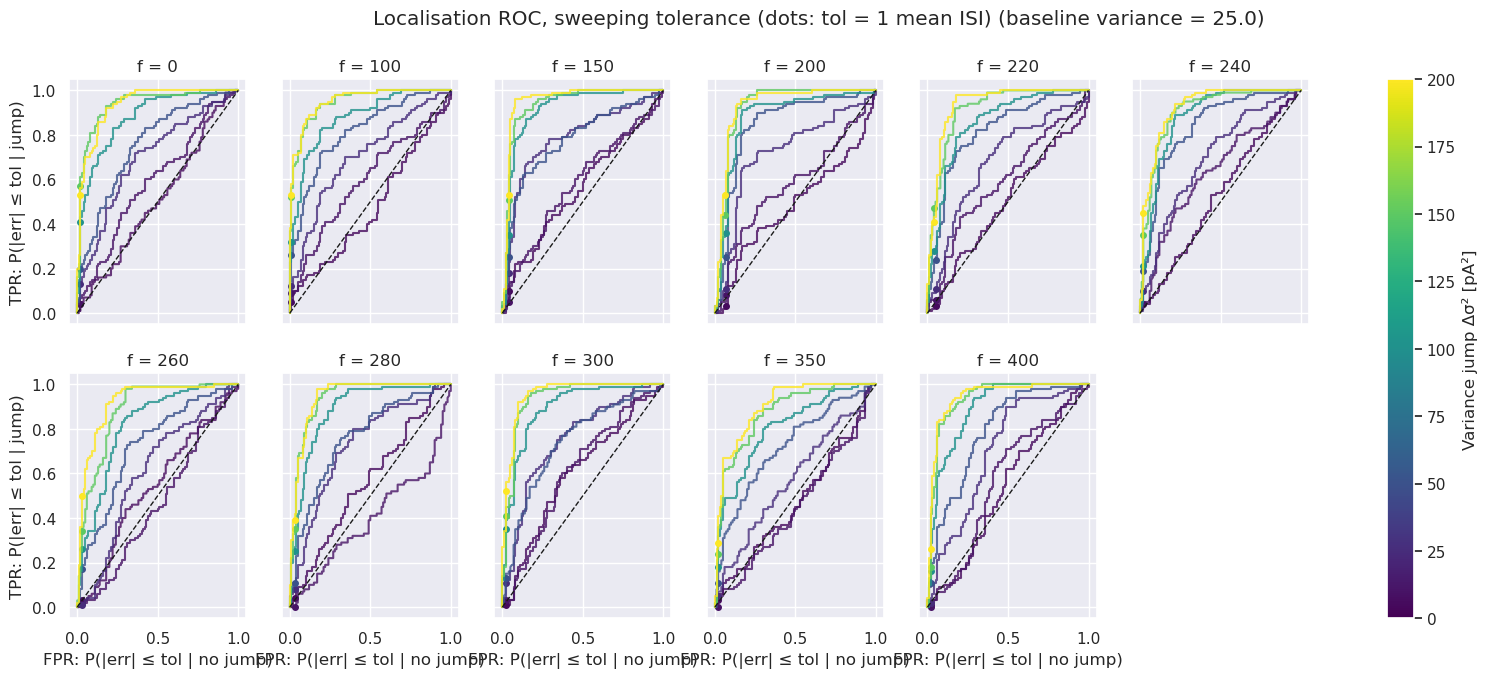

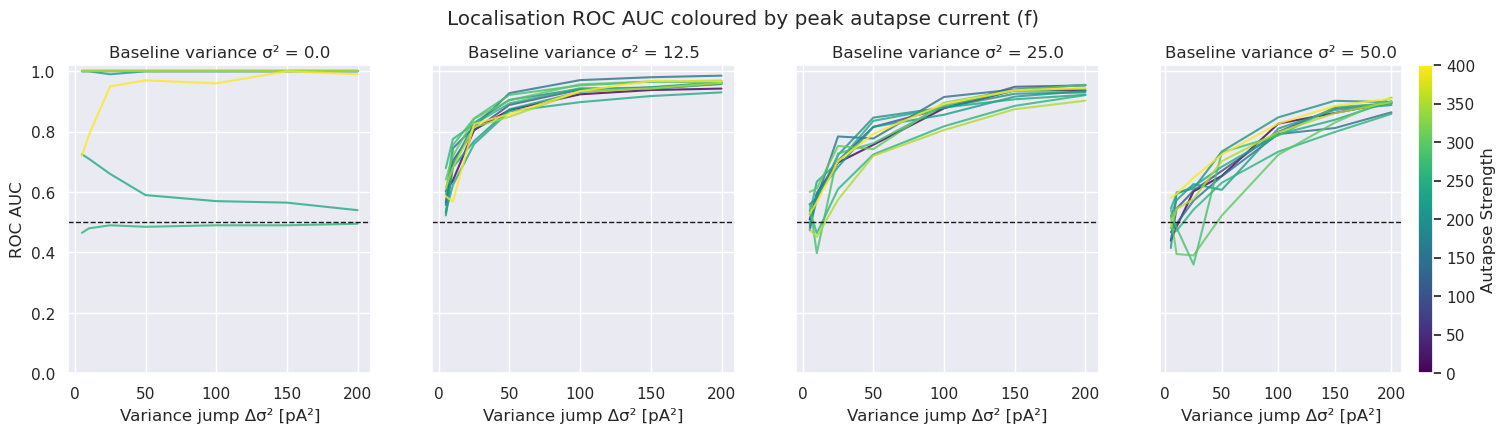

In [11]:
tol_ref_ms = 100

roc, roc_auc = tolerance_roc(data, true_cp, step_col = STEP)


def plot_roc(a, f):
    df = roc[(roc['autapse f'] == f) & (roc['variance'] == v_plot)]
    for dv, d in df.groupby(STEP):
        c = cm.viridis(step_norm(dv))
        a.plot(d['FPR'], d['TPR'], color = c, alpha = 0.8)
        if TOL_MODE == 'isi':
            sel = (isi_df['variance'] == v_plot) & (isi_df[STEP] == dv) & (isi_df['autapse f'] == f)
            t_ref = isi_df.loc[sel, 'mean ISI'].iloc[0]
        else:
            t_ref = tol_ref_ms
        op = d[d['tol [ms]'] <= t_ref].iloc[-1]
        a.plot(op['FPR'], op['TPR'], 'o', color = c, markersize = 4)
    a.plot([0, 1], [0, 1], 'k--', lw = 1)

op_label = '1 mean ISI' if TOL_MODE == 'isi' else f'{tol_ref_ms} ms'
fig, ax = per_f_grid(plot_roc, f'Localisation ROC, sweeping tolerance (dots: tol = {op_label})',
                     'FPR: P(|err| ≤ tol | no jump)', 'TPR: P(|err| ≤ tol | jump)')
if SAVE: plt.savefig(f'./plots/var_{tag}_tolerance_ROC.png', bbox_inches = 'tight')
plt.show()

fig, ax = by_variance(roc_auc, 'AUC', 'ROC AUC', title = 'Localisation ROC AUC coloured by peak autapse current (f)')
for a in ax:
    a.axhline(0.5, color = 'k', ls = '--', lw = 1)
    a.set_ylim((0, 1.02))
if SAVE: plt.savefig(f'./plots/var_{tag}_tolerance_ROC_AUC.png', bbox_inches = 'tight')

#### Histograms of estimated change point times
Rows: autapse strength. Columns: baseline variance. One variance jump (`DV_HIST`), pooled over repeats.

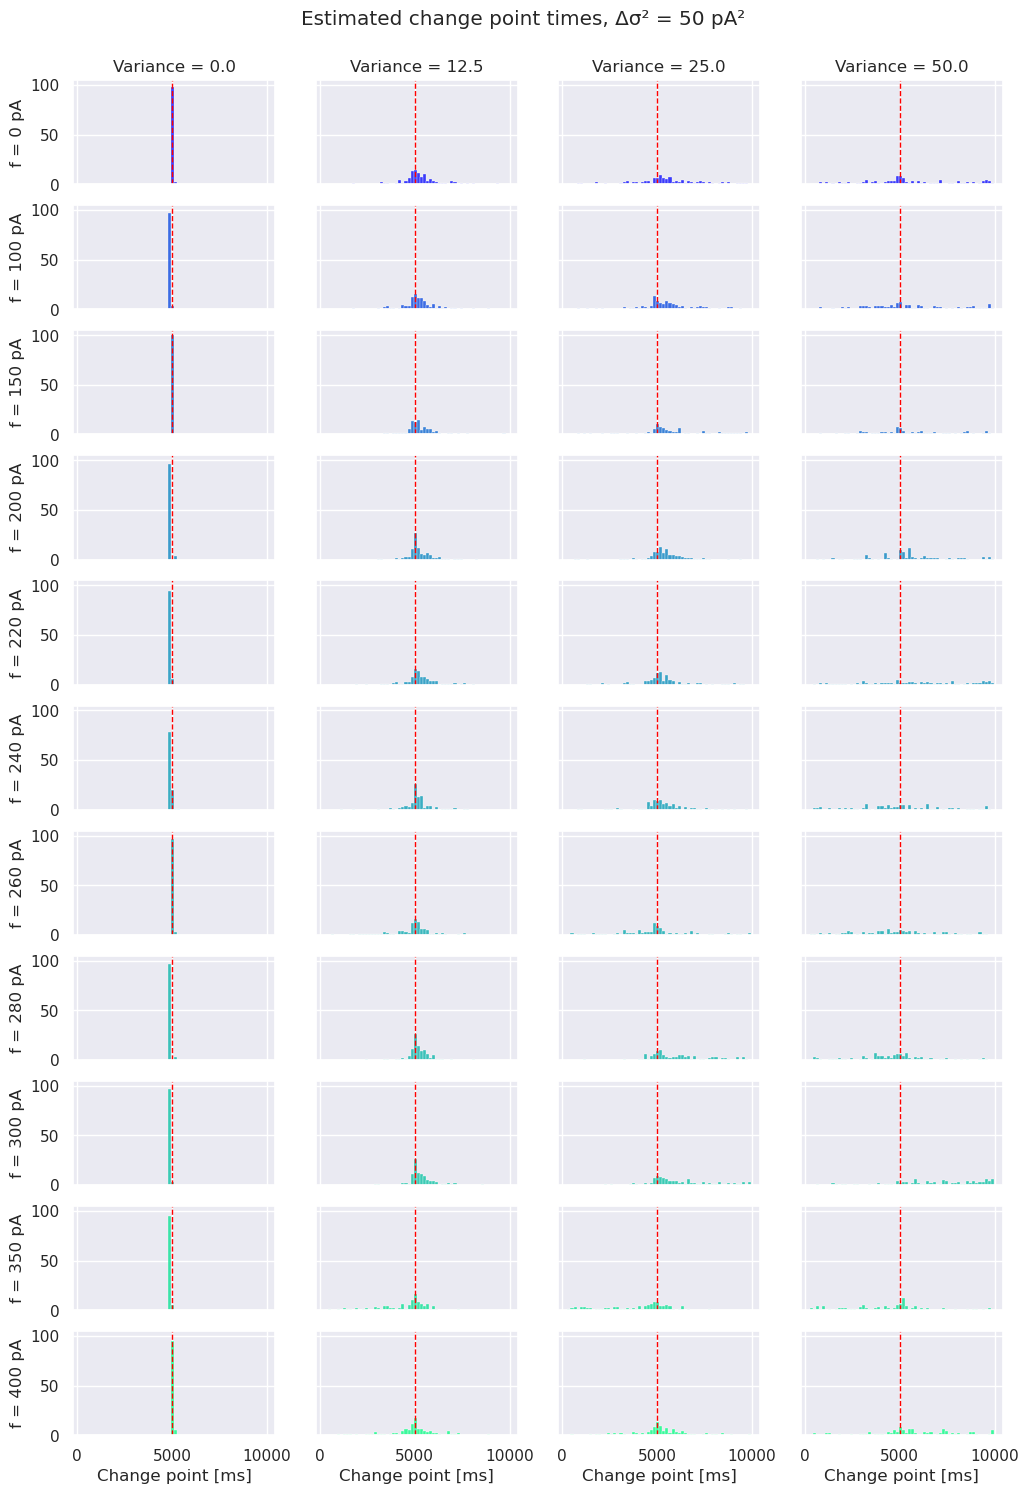

In [12]:
DV_HIST = 50
fig, ax = changepoint_distribution(data[data[STEP] == DV_HIST], x = 'change point', row = 'autapse f', col = 'variance',
                                   add_colorbar = False, true_cp = true_cp)
fig.suptitle(f'Estimated change point times, Δσ² = {DV_HIST} pA²', y = 0.92)
if SAVE: plt.savefig(f'./plots/var_{tag}_CP_hist.png', bbox_inches = 'tight')

### 3. Divergence measures
These come from the fitted pre/post (pair) distributions. They describe each **condition**, not each trial, so they say how decodable the variance jump is in principle. Units are nats; Fisher information is about the noise variance (nats/pA⁴). `DROP_ZERO_BASELINE` removes σ² = 0.

| Column | Meaning |
|---|---|
| `KL post\|\|pre`, `KL pre\|\|post` | KL divergence in each direction, per ISI |
| `divergence` | Jeffreys J = sum of the two KLs, per ISI |
| `divergence per s` | J weighted by the pre/post firing rates, per second |
| `JS divergence` | Jensen–Shannon divergence, per ISI, ≤ ln 2 |
| `fisher local` (`per s`) | J / (Δσ²)², from each condition's pre/post pair; only accurate for small Δσ² |
| `fisher` (`per s`) | Fisher information at σ² + Δσ², from the post distributions of neighbouring jumps |

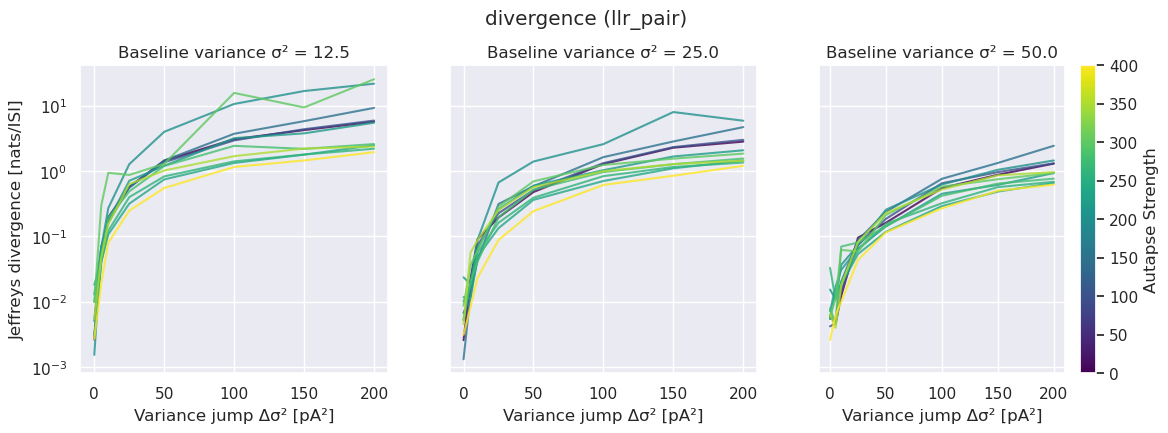

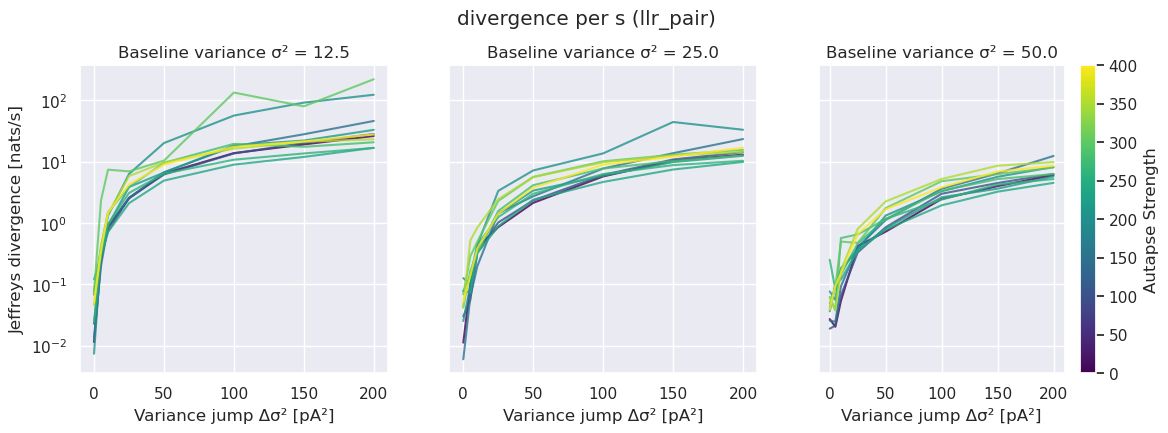

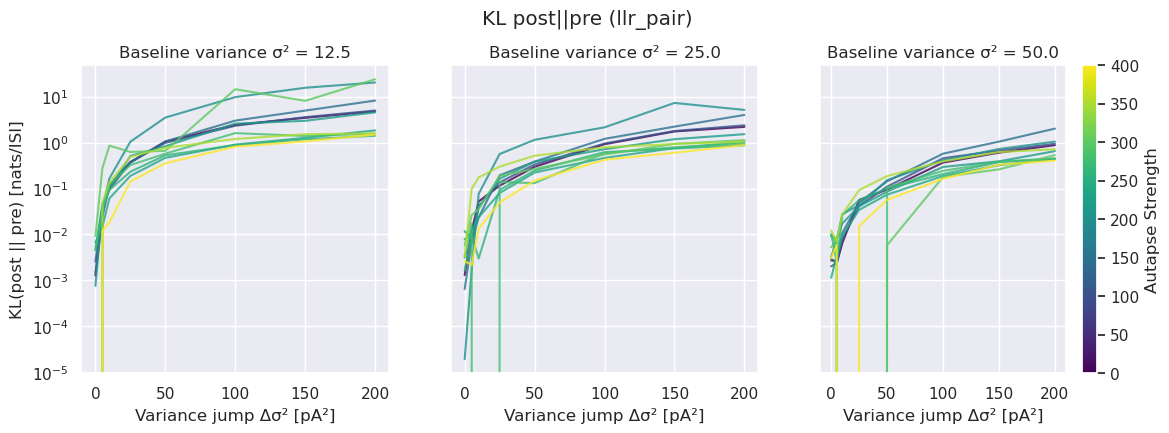

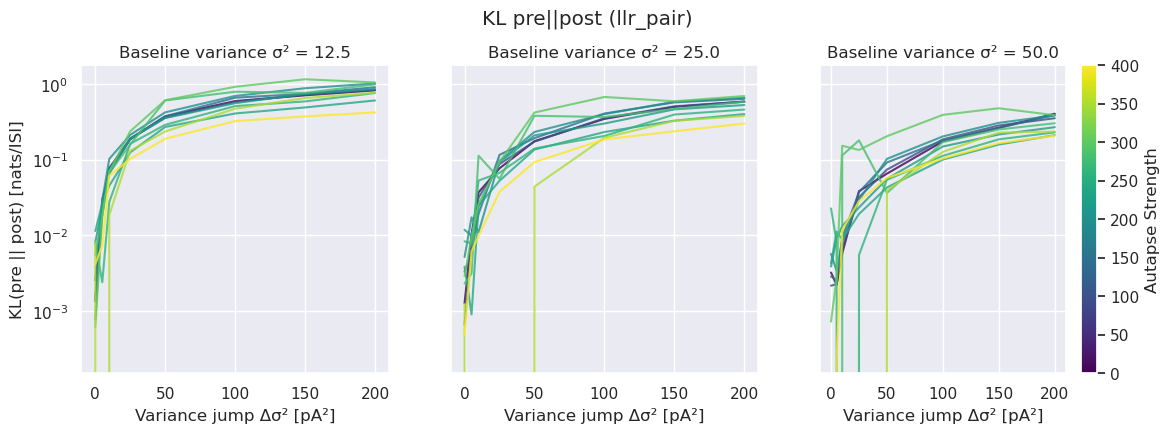

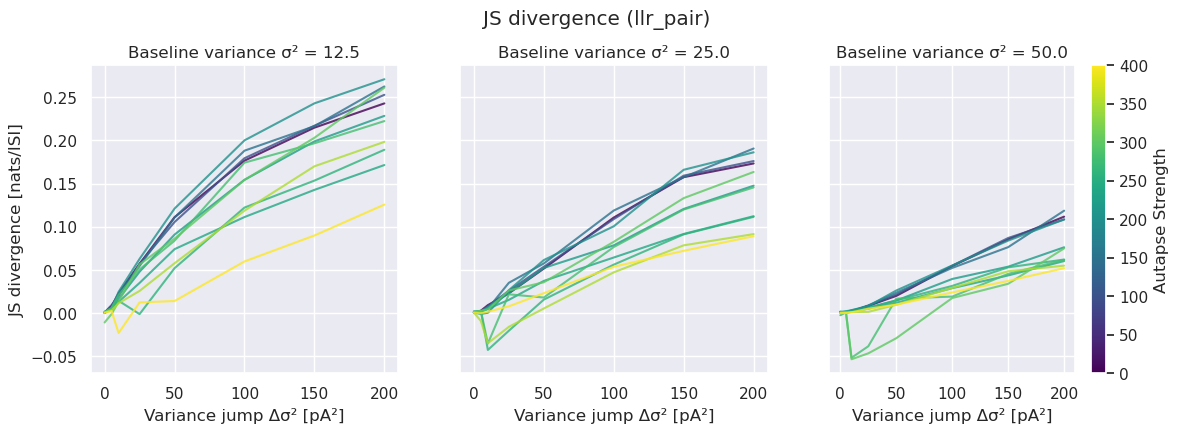

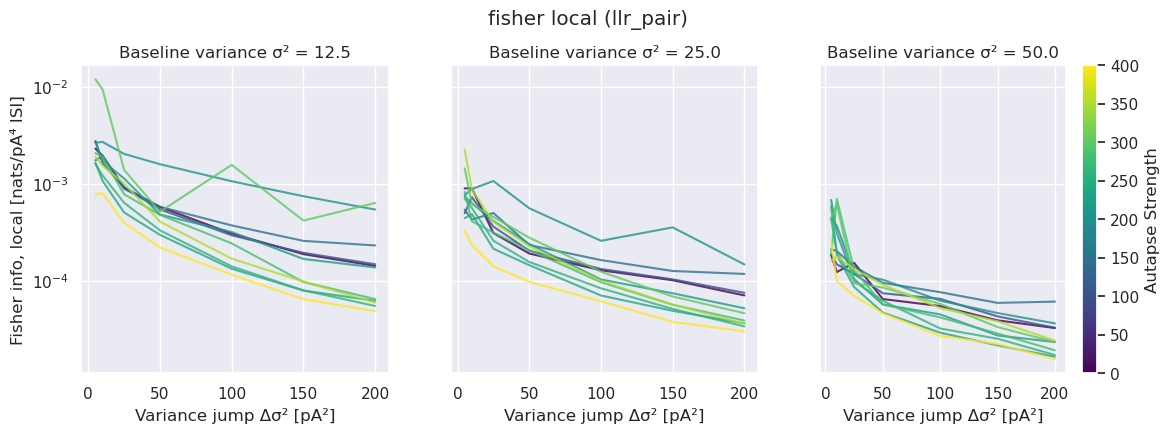

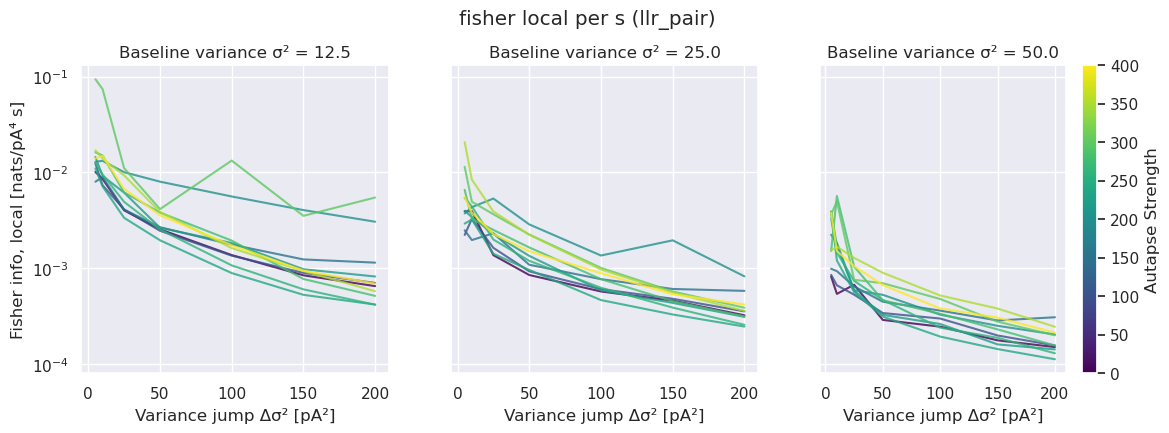

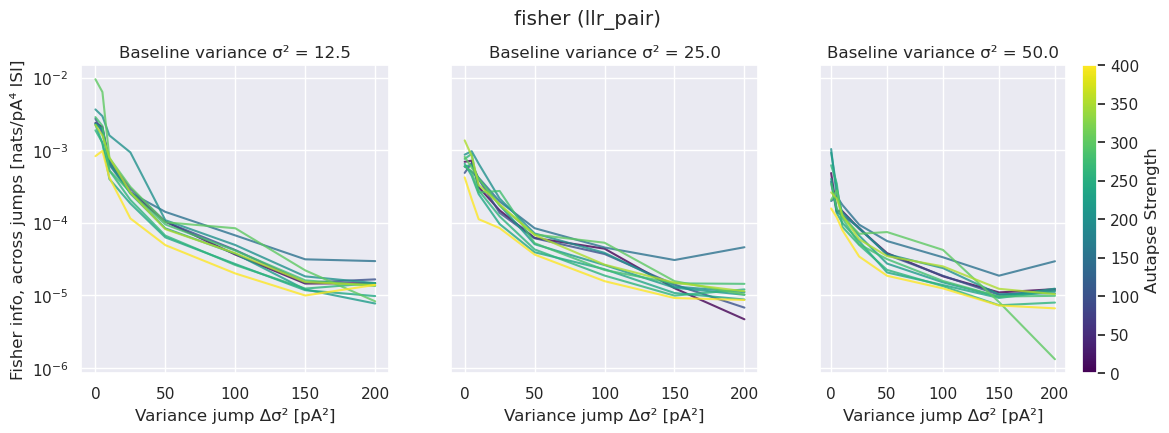

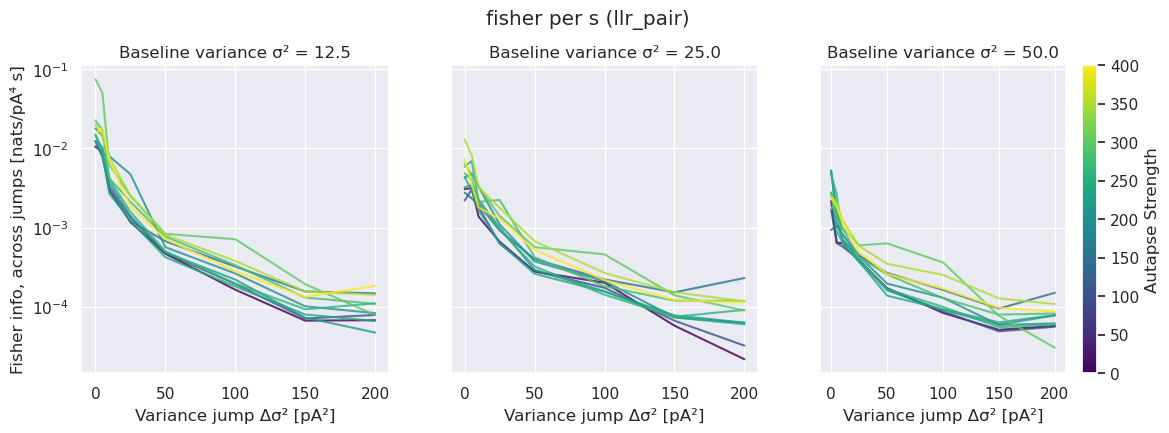

In [13]:
cond = cond_all[cond_all['variance'] != 0.0] if DROP_ZERO_BASELINE else cond_all
div_vars = np.sort(cond['variance'].unique())

MEASURES = {
    'divergence':          ('Jeffreys divergence [nats/ISI]', True),
    'divergence per s':    ('Jeffreys divergence [nats/s]', True),
    'KL post||pre':        ('KL(post || pre) [nats/ISI]', True),
    'KL pre||post':        ('KL(pre || post) [nats/ISI]', True),
    'JS divergence':       ('JS divergence [nats/ISI]', False),
    'fisher local':        ('Fisher info, local [nats/pA⁴ ISI]', True),
    'fisher local per s':  ('Fisher info, local [nats/pA⁴ s]', True),
    'fisher':              ('Fisher info, across jumps [nats/pA⁴ ISI]', True),
    'fisher per s':        ('Fisher info, across jumps [nats/pA⁴ s]', True),
}

for y, (label, log) in MEASURES.items():
    by_variance(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_{y.replace(" ", "_").replace("||", "_")}_diff_V.png', bbox_inches = 'tight')
    plt.show()

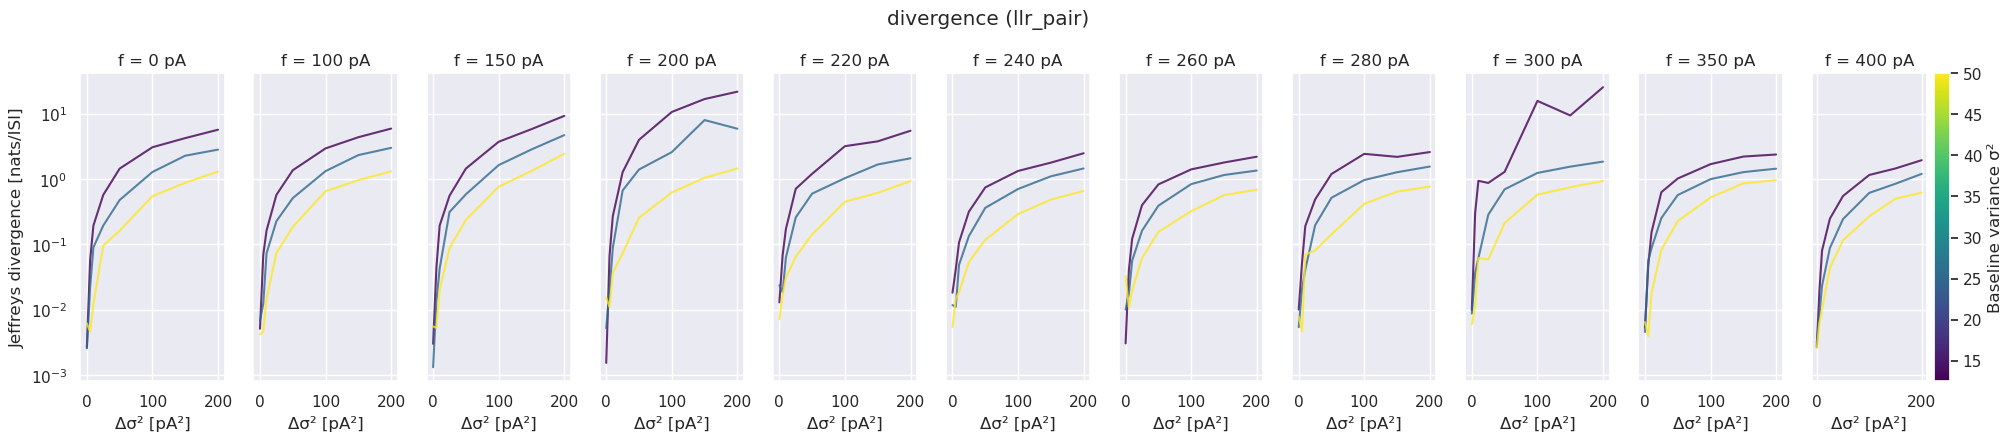

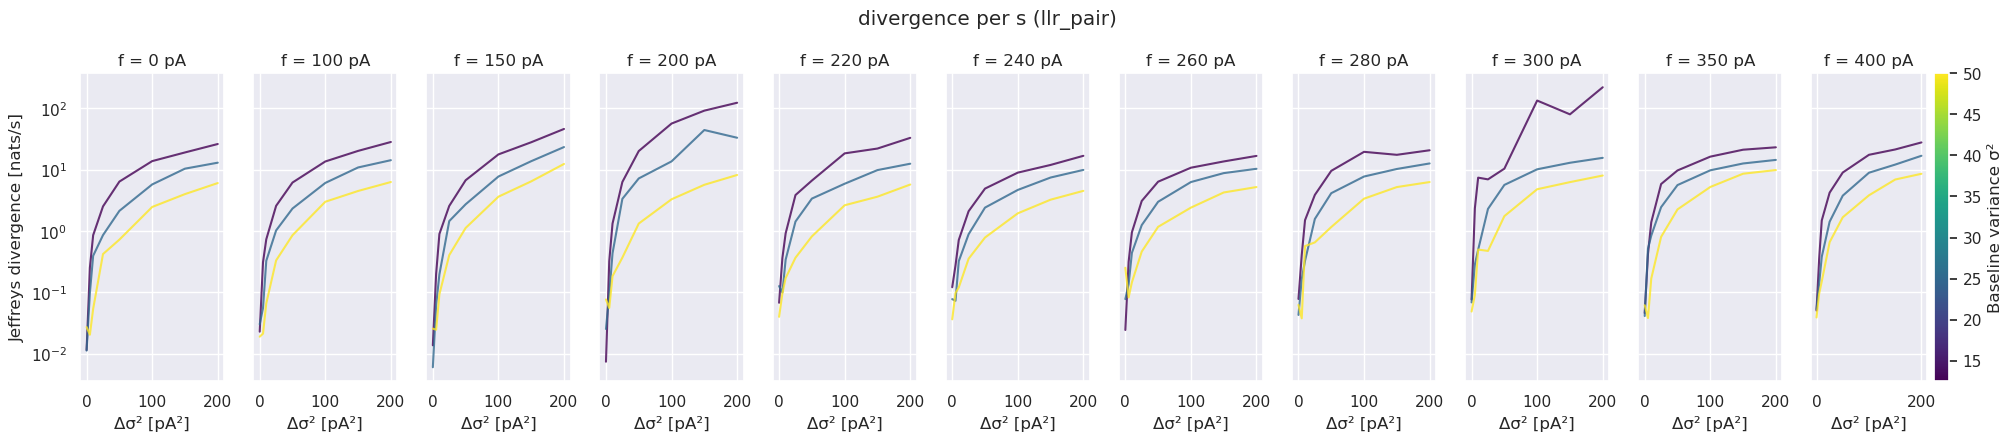

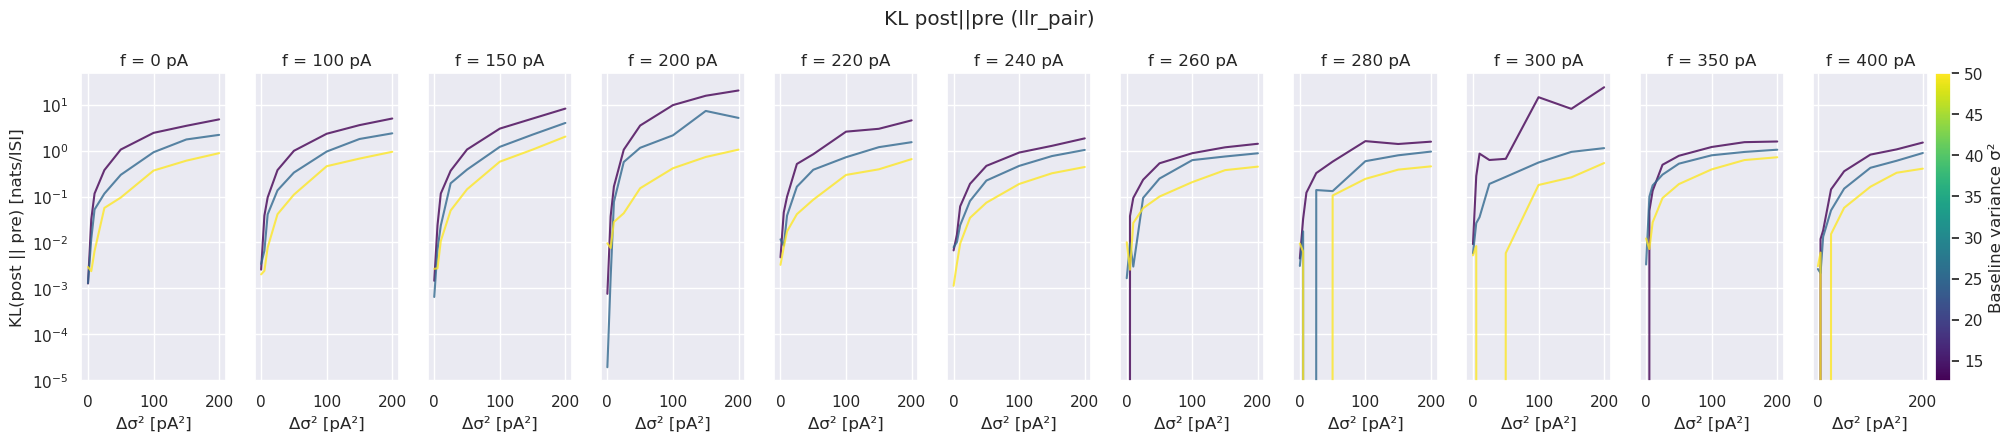

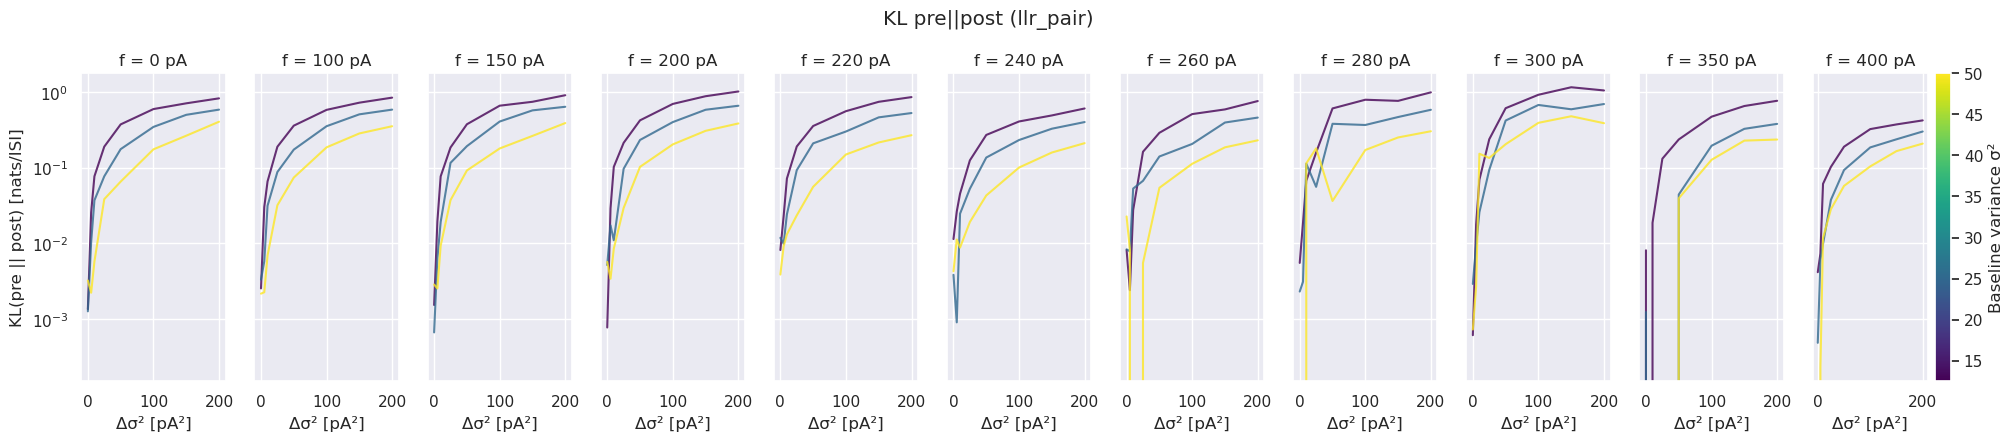

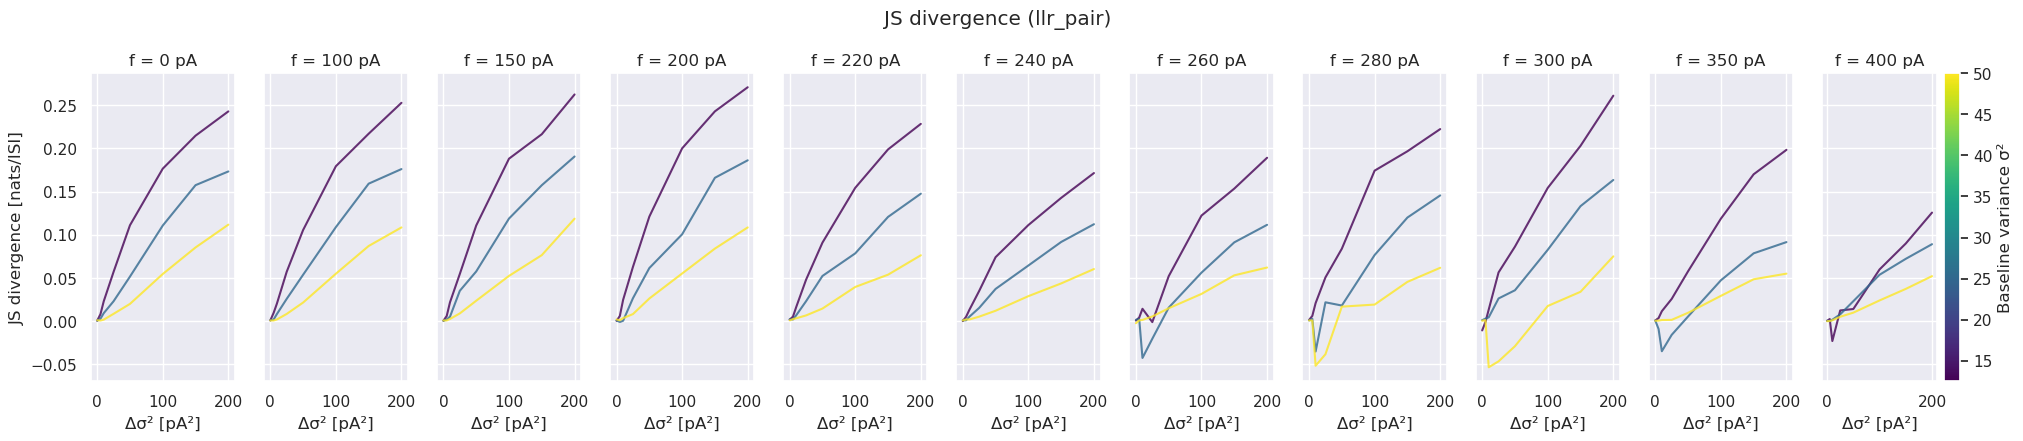

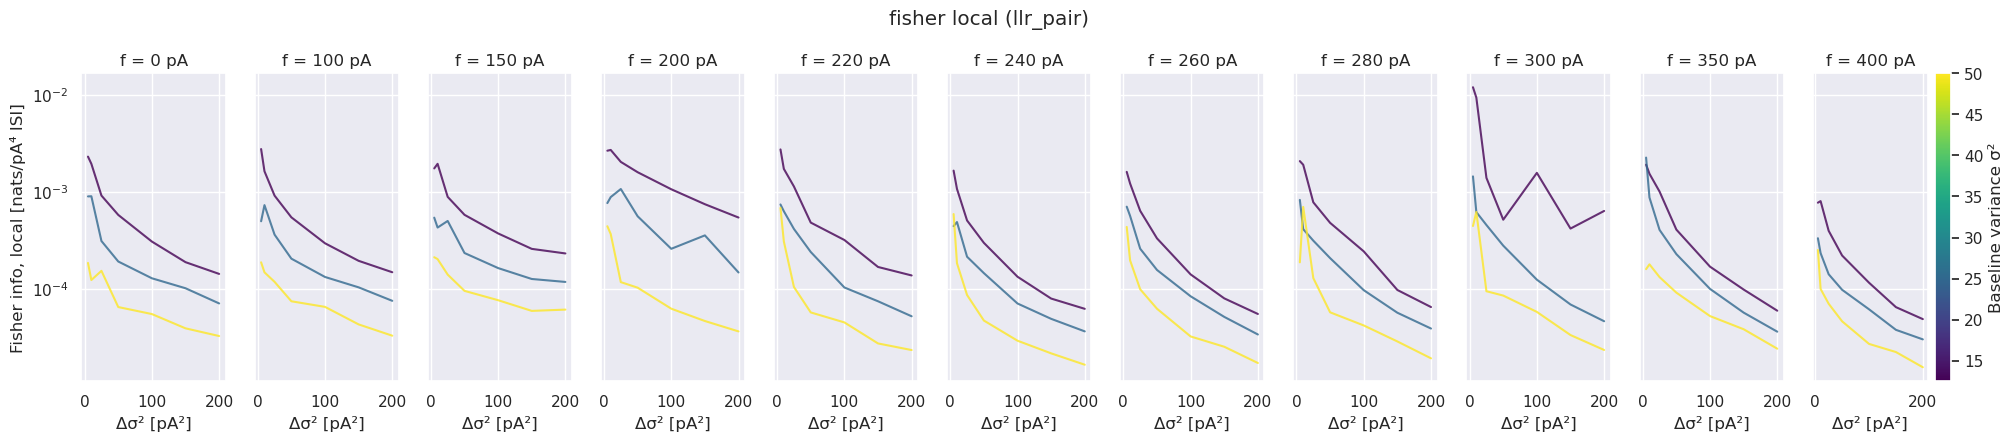

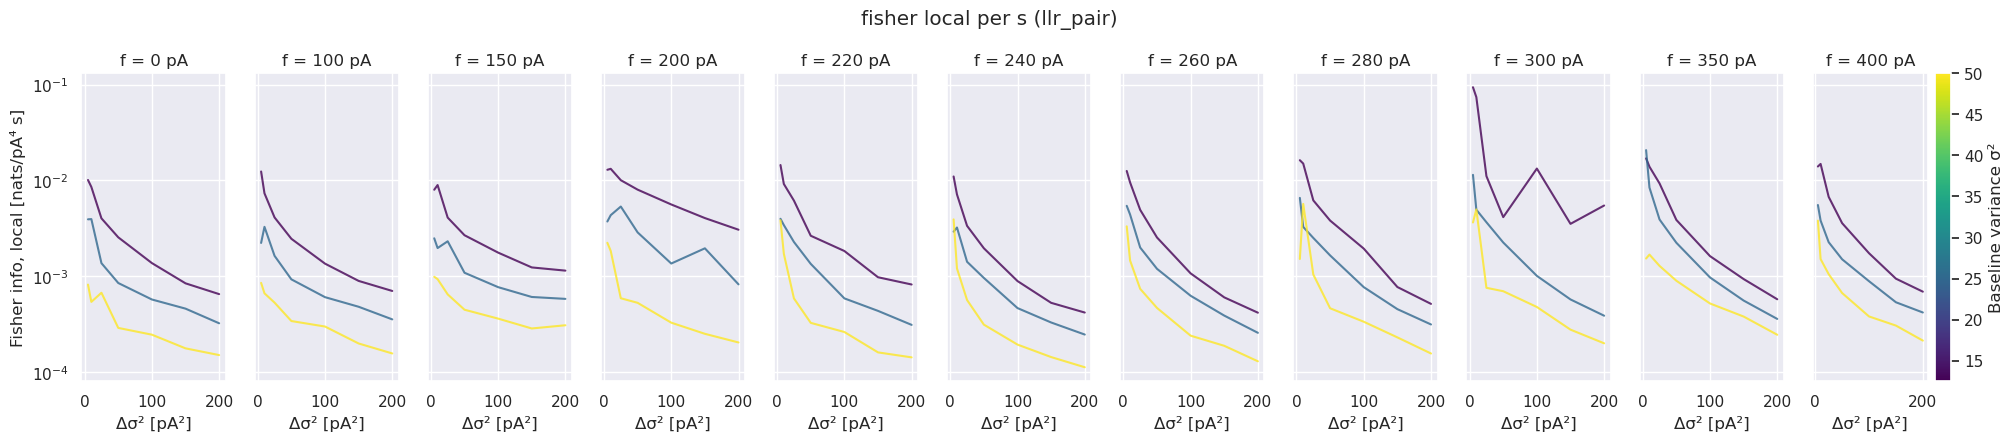

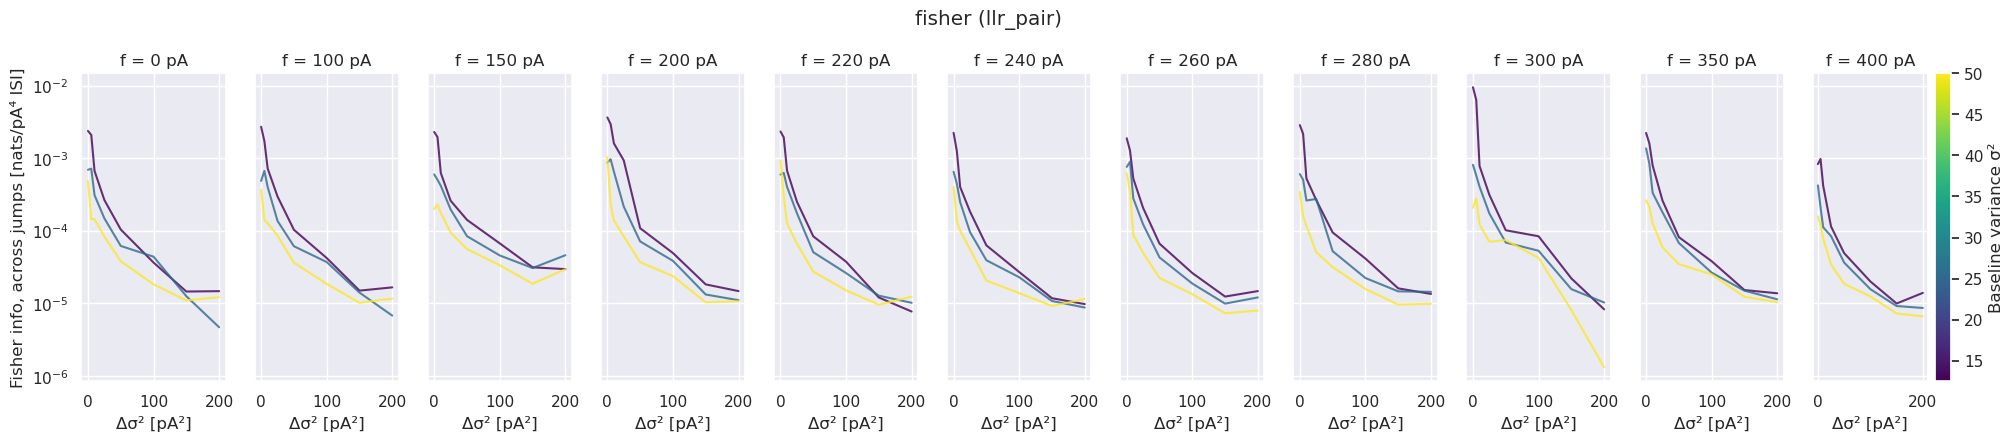

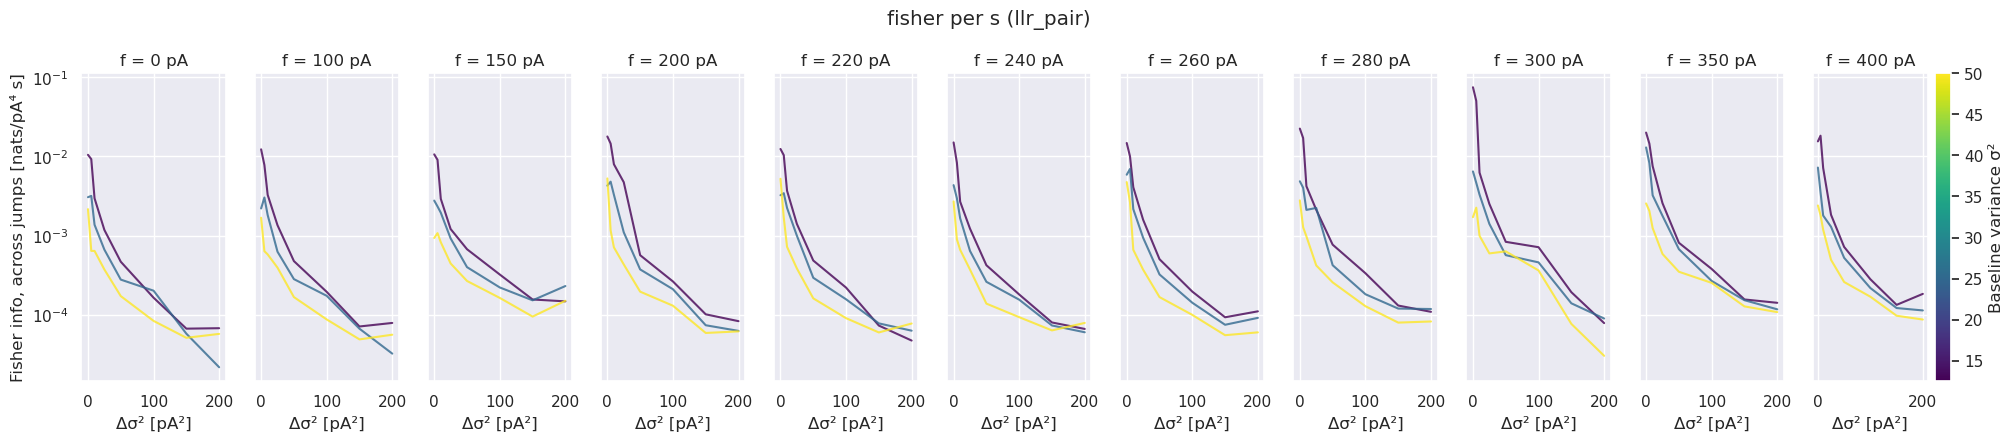

In [14]:
for y, (label, log) in MEASURES.items():
    by_neuron(cond, y, label, log)
    if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_{y.replace(" ", "_").replace("||", "_")}_diff_autapse.png', bbox_inches = 'tight')
    plt.show()

#### Mean of each measure over Δσ², against autapse strength
`curve_auc` with `normalise = True`, one curve per (f, σ²). There is one value per condition, so there is no error band.

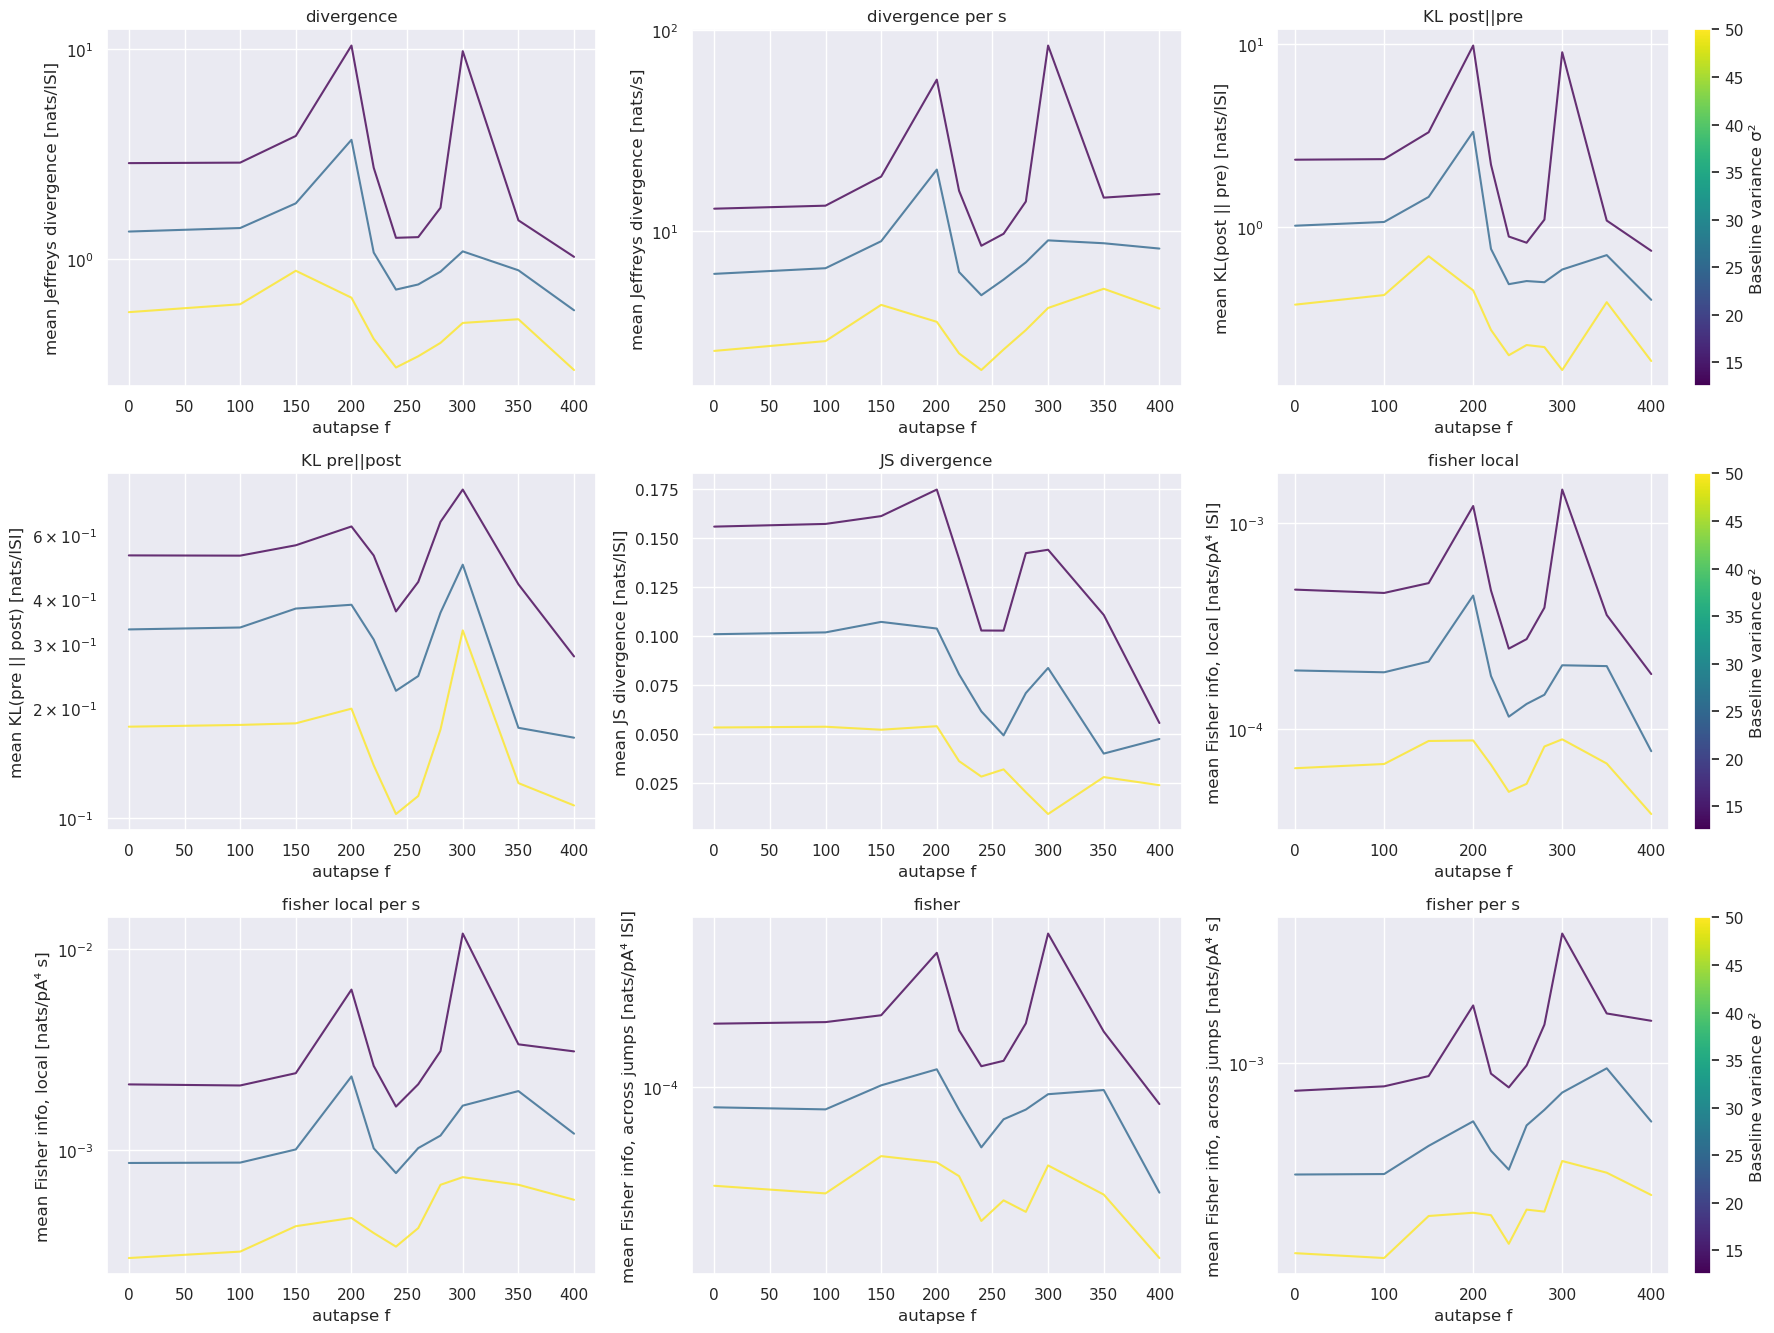

In [15]:
ys = list(MEASURES)
fig, ax = plt.subplots(int(np.ceil(len(ys)/3)), 3, figsize = (18, 4.5*np.ceil(len(ys)/3)), squeeze = False)
ax = ax.ravel()
for n, y in enumerate(ys):
    auc = curve_auc(cond.dropna(subset = [y]), y = y, x = STEP, group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(auc, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n % 3 == 2,
                          colorbar_label = 'Baseline variance σ²')
    ax[n].set_title(y)
    ax[n].set_ylabel(f'mean {MEASURES[y][0]}')
    if MEASURES[y][1]:
        ax[n].set_yscale('log')
for a in ax[len(ys):]:
    a.set_visible(False)
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_divergence_AUC_vs_f.png', bbox_inches = 'tight')

#### Divergence maps (autapse f × Δσ²)

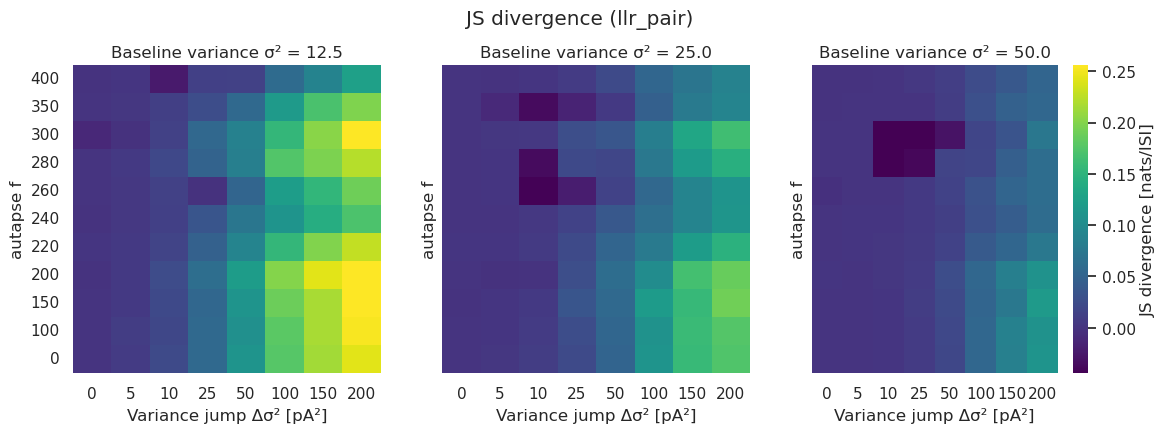

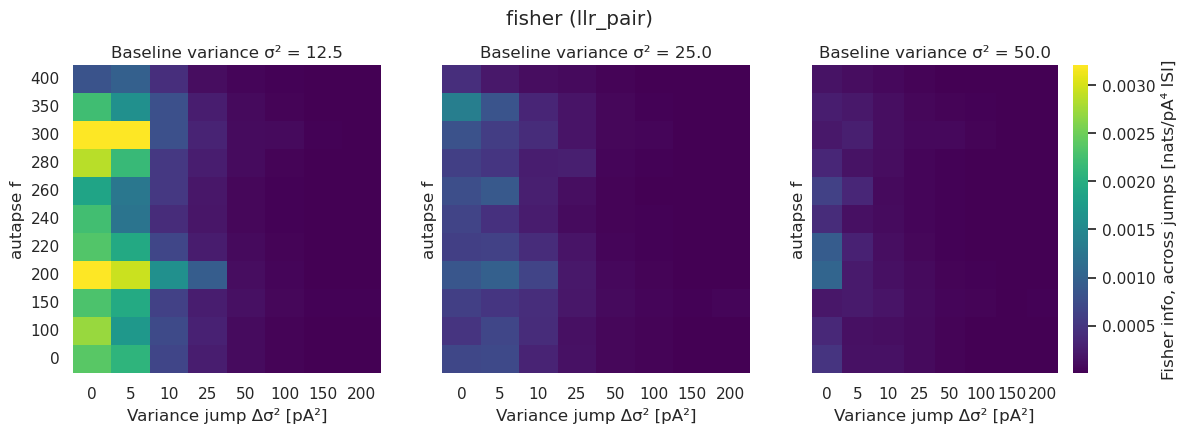

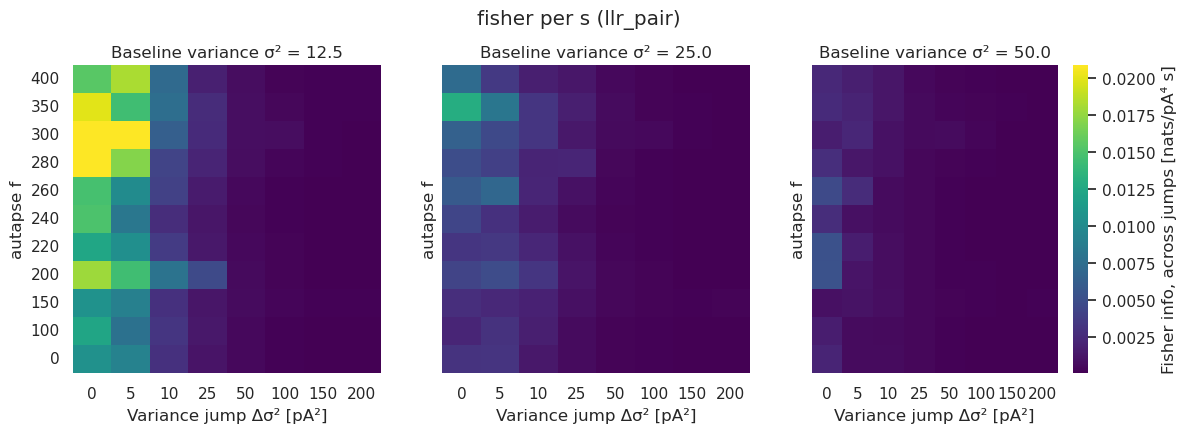

In [16]:
for y in ['JS divergence', 'fisher', 'fisher per s']:
    fig, ax = plt.subplots(1, len(div_vars), figsize = (4.5*len(div_vars), 4), sharey = True, squeeze = False)
    ax = ax[0]
    vmin, vmax = np.nanpercentile(cond[y], [1, 99])
    for n, v in enumerate(div_vars):
        m = cond[cond['variance'] == v].pivot(index = 'autapse f', columns = STEP, values = y)
        sns.heatmap(m, ax = ax[n], cmap = 'viridis', vmin = vmin, vmax = vmax, cbar = n == len(div_vars) - 1,
                    cbar_kws = {'label': MEASURES[y][0]})
        ax[n].invert_yaxis()
        ax[n].set_title(f'Baseline variance σ² = {v}')
        ax[n].set_xlabel(XLABEL)
    fig.suptitle(f'{y} ({method})', y = 1.02)
    if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_{y.replace(" ", "_")}_map.png', bbox_inches = 'tight')
    plt.show()

#### Checks
1. **Local vs across-jump Fisher information.** These should agree for small Δσ².
2. **Evidence collected vs available.** `score per s` (per trial, averaged over repeats) against `divergence per s`. Points below the diagonal: the CUSUM collects less evidence than the fits predict.

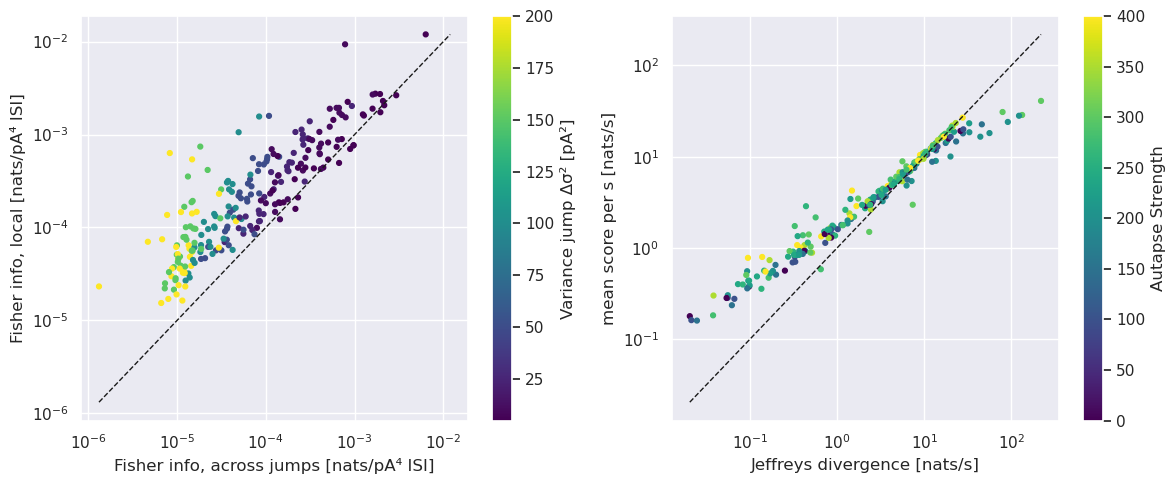

In [17]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))

sub = cond[cond[STEP] > 0]
sc = ax[0].scatter(sub['fisher'], sub['fisher local'], c = sub[STEP], cmap = 'viridis', s = 12)
lims = [np.nanmin(sub[['fisher', 'fisher local']].values), np.nanmax(sub[['fisher', 'fisher local']].values)]
ax[0].plot(lims, lims, 'k--', lw = 1)
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Fisher info, across jumps [nats/pA⁴ ISI]')
ax[0].set_ylabel('Fisher info, local [nats/pA⁴ ISI]')
fig.colorbar(sc, ax = ax[0], label = XLABEL)

d = data[data['variance'].isin(div_vars)]
ev = d.groupby(cond_cols, as_index = False)[['score per s', 'divergence per s']].mean()
ev = ev[ev[STEP] > 0]
sc = ax[1].scatter(ev['divergence per s'], ev['score per s'], c = ev['autapse f'], cmap = 'viridis', s = 12)
lims = [max(np.nanmin(ev['divergence per s']), 1e-3), np.nanmax(ev['divergence per s'])]
ax[1].plot(lims, lims, 'k--', lw = 1)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('Jeffreys divergence [nats/s]')
ax[1].set_ylabel('mean score per s [nats/s]')
fig.colorbar(sc, ax = ax[1], label = 'Autapse Strength')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_divergence_checks.png', bbox_inches = 'tight')

### 4. Model-free distances between the pooled pre and post ISIs
These compare the empirical (pooled) ISIs directly, with no fit: the KS statistic (0–1), the energy distance [ms], and the energy distance of log(ISI). They only use the 1D ISIs, so they ignore the pair (burst) structure that `llr_pair` models.

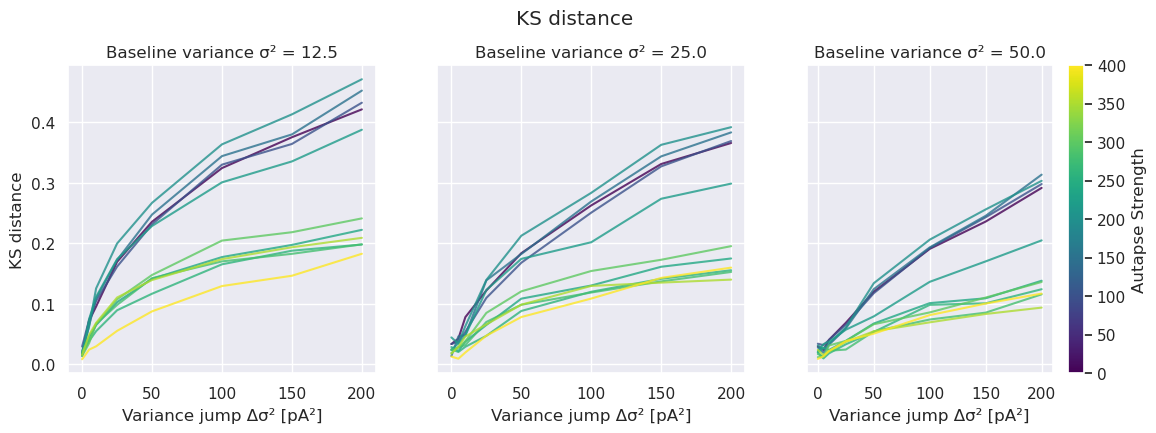

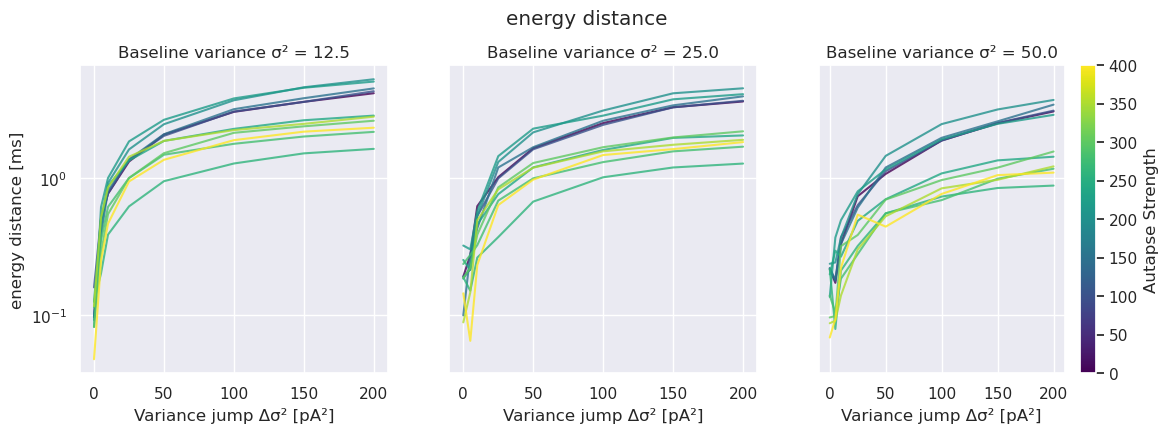

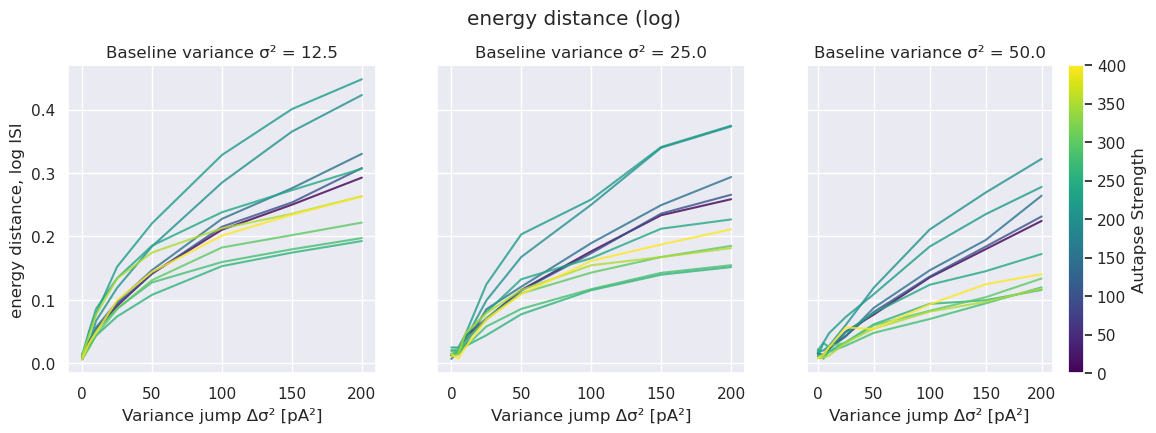

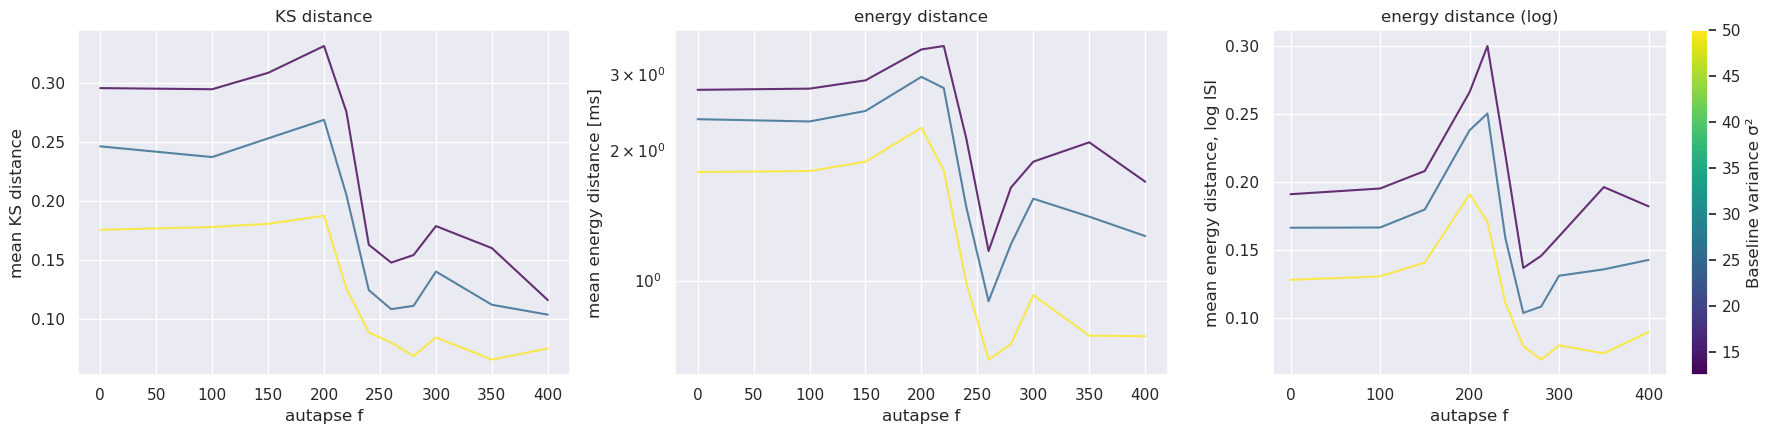

In [18]:
EMPIRICAL = {
    'KS distance':           ('KS distance', False),
    'energy distance':       ('energy distance [ms]', True),
    'energy distance (log)': ('energy distance, log ISI', False),
}

for y, (label, log) in EMPIRICAL.items():
    by_variance(cond, y, label, log, title = y)
    if SAVE: plt.savefig(f'./plots/var_{tag}_{y.replace(" ", "_")}_diff_V.png', bbox_inches = 'tight')
    plt.show()

fig, ax = plt.subplots(1, len(EMPIRICAL), figsize = (6*len(EMPIRICAL), 4.5), squeeze = False)
ax = ax[0]
for n, (y, (label, log)) in enumerate(EMPIRICAL.items()):
    auc = curve_auc(cond.dropna(subset = [y]), y = y, x = STEP, group_cols = ('autapse f', 'variance'), normalise = True)
    fig, ax[n] = auc_plot(auc, fig = fig, ax = ax[n], errorbar = None, add_colorbar = n == len(EMPIRICAL) - 1,
                          colorbar_label = 'Baseline variance σ²')
    ax[n].set_title(y)
    ax[n].set_ylabel(f'mean {label}')
    if log: ax[n].set_yscale('log')
fig.tight_layout()
if SAVE: plt.savefig(f'./plots/var_{tag}_empirical_distance_AUC_vs_f.png', bbox_inches = 'tight')

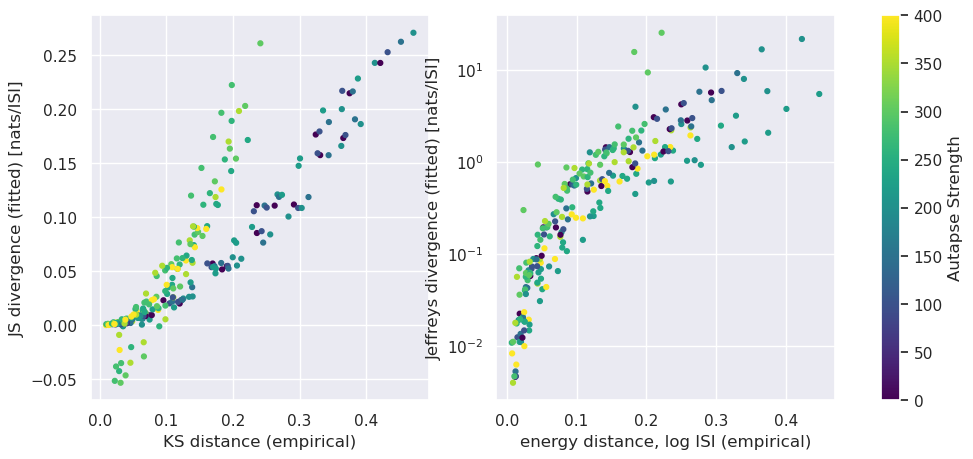

In [19]:
fig, ax = plt.subplots(1, 2, figsize = (12, 5))
sub = cond[cond[STEP] > 0]

sc = ax[0].scatter(sub['KS distance'], sub['JS divergence'], c = sub['autapse f'], cmap = 'viridis', s = 12)
ax[0].set_xlabel('KS distance (empirical)')
ax[0].set_ylabel('JS divergence (fitted) [nats/ISI]')

sc = ax[1].scatter(sub['energy distance (log)'], sub['divergence'], c = sub['autapse f'], cmap = 'viridis', s = 12)
ax[1].set_yscale('log')
ax[1].set_xlabel('energy distance, log ISI (empirical)')
ax[1].set_ylabel('Jeffreys divergence (fitted) [nats/ISI]')

fig.colorbar(sc, ax = ax, label = 'Autapse Strength')
if SAVE: plt.savefig(f'./plots/var_{tag}_{method}_empirical_vs_fitted.png', bbox_inches = 'tight')